1ST DATA SET AUDIT DATA **CLEANING**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("combined_gee_pm25.csv")

In [ ]:
# ============================================================
# PART 1 – DATASET AUDIT & DATA CLEANING
# STEP 1 – INITIAL DATASET EXPLORATION
# ============================================================




# 3. Dataset Dimensions
print("\n2. DATASET DIMENSIONS")
print("Number of rows and columns:", df.shape)
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

# 4. Display First Rows
print("\n3. FIRST 5 ROWS")
display(df.head())

# 5. Dataset Information
print("\n4. DATASET INFORMATION")
df.info()

# 6. Column Names
print("\n5. COLUMN NAMES")
print(df.columns.tolist())

# 7. Data Types
print("\n6. DATA TYPES")
print(df.dtypes)

# 8. Descriptive Statistics
print("\n7. DESCRIPTIVE STATISTICS")
display(df.describe(include="all").T)

# 9. Missing Values Analysis
print("\n8. MISSING VALUES ANALYSIS")

missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

# 10. Duplicate Analysis
print("\n9. DUPLICATE ANALYSIS")

print("Number of complete duplicate rows:", df.duplicated().sum())

# 11. Unique Values
print("\n10. NUMBER OF UNIQUE VALUES")

unique_values = df.nunique()
display(unique_values.to_frame(name="Unique_Count"))

# 12. PM2.5 Basic Analysis
print("\n11. PM2.5 TARGET VARIABLE ANALYSIS")

if "pm25_ugm3" in df.columns:

    print("PM2.5 descriptive statistics:")
    display(df["pm25_ugm3"].describe())

    print("\nMissing PM2.5 values:", df["pm25_ugm3"].isnull().sum())

    print("PM2.5 values <= 0:",
          (df["pm25_ugm3"] <= 0).sum())

    print("PM2.5 values >= 500:",
          (df["pm25_ugm3"] >= 500).sum())

else:
    print("WARNING: PM2.5 column not found.")
    print("Available columns:", df.columns.tolist())

# 13. Dataset Date Range
print("\n12. DATE RANGE")

date_columns = [
    col for col in df.columns
    if "date" in col.lower() or "time" in col.lower()
]

for col in date_columns:
    dates = pd.to_datetime(df[col], errors="coerce")
    print(f"\nColumn: {col}")
    print("Minimum date:", dates.min())
    print("Maximum date:", dates.max())
    print("Invalid dates:", dates.isna().sum())

# 14. Station Analysis
print("\n13. STATION ANALYSIS")

station_columns = [
    col for col in df.columns
    if "station" in col.lower() or col.lower() == "node_id"
]

for col in station_columns:
    print(f"\nStation column: {col}")
    print("Number of unique stations:", df[col].nunique())
    print("Missing station IDs:", df[col].isnull().sum())

# 15. Numerical Variables Distribution
print("\n14. NUMERICAL VARIABLES")

display(df.select_dtypes(include=np.number).describe().T)




2. DATASET DIMENSIONS
Number of rows and columns: (41718, 15)
Number of observations: 41718
Number of variables: 15

3. FIRST 5 ROWS


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT



4. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41718 entries, 0 to 41717
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 41718 non-null  object 
 1   datetime_utc         41718 non-null  object 
 2   id                   41718 non-null  int64  
 3   latitude             41718 non-null  float64
 4   longitude            41718 non-null  float64
 5   temperature_celsius  41718 non-null  float64
 6   pressure_mb          41718 non-null  float64
 7   wind_u               41718 non-null  float64
 8   wind_v               41718 non-null  float64
 9   NO2                  39308 non-null  float64
 10  CO                   39308 non-null  float64
 11  O3                   39267 non-null  float64
 12  AOD                  41718 non-null  float64
 13  pm25                 41718 non-null  float64
 14  sensor_name          41718 non-null  object 
dtypes: float64(1

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,41718,2305,2024-05-28,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
datetime_utc,41718,2305,2024-05-28 00:00:00,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,41718.0,NaN,NaN,NaN,52.301333,35.07528,0.0,21.0,48.0,90.0,109.0
latitude,41718.0,NaN,NaN,NaN,39.032749,2.225799,36.133317,36.84133,39.44833,40.051944,43.530297
longitude,41718.0,NaN,NaN,NaN,-0.47253,3.81618,-5.6635,-3.61266,-0.40605,1.1496,9.136389
temperature_celsius,41718.0,NaN,NaN,NaN,18.334932,6.382068,-1.279053,13.019105,18.594874,23.863248,34.865831
pressure_mb,41718.0,NaN,NaN,NaN,993.702935,17.241096,930.317065,987.757065,997.64155,1005.290895,1033.662176
wind_u,41718.0,NaN,NaN,NaN,0.336047,2.524131,-11.098723,-0.992154,0.190988,1.671555,9.661651
wind_v,41718.0,NaN,NaN,NaN,-0.173491,1.383497,-10.860048,-0.720651,0.047318,0.663616,8.486383
NO2,39308.0,NaN,NaN,NaN,0.000091,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483



8. MISSING VALUES ANALYSIS


,Missing_Count,Missing_Percentage
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,2410,5.776883



9. DUPLICATE ANALYSIS
Number of complete duplicate rows: 0

10. NUMBER OF UNIQUE VALUES


,Unique_Count
date,2305
datetime_utc,2305
id,98
latitude,98
longitude,98
temperature_celsius,29911
pressure_mb,29911
wind_u,29900
wind_v,29916
NO2,27929



11. PM2.5 TARGET VARIABLE ANALYSIS
Available columns: ['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']

12. DATE RANGE

Column: date
Minimum date: 2016-11-25 00:00:00
Maximum date: 2026-04-06 00:00:00
Invalid dates: 0

Column: datetime_utc
Minimum date: 2016-11-25 00:00:00
Maximum date: 2026-04-06 00:00:00
Invalid dates: 0

13. STATION ANALYSIS

14. NUMERICAL VARIABLES


,count,mean,std,min,25%,50%,75%,max
id,41718.0,52.301333,35.075280,0.000000,21.000000,48.000000,90.000000,109.000000
latitude,41718.0,39.032749,2.225799,36.133317,36.841330,39.448330,40.051944,43.530297
longitude,41718.0,-0.472530,3.816180,-5.663500,-3.612660,-0.406050,1.149600,9.136389
temperature_celsius,41718.0,18.334932,6.382068,-1.279053,13.019105,18.594874,23.863248,34.865831
pressure_mb,41718.0,993.702935,17.241096,930.317065,987.757065,997.641550,1005.290895,1033.662176
wind_u,41718.0,0.336047,2.524131,-11.098723,-0.992154,0.190988,1.671555,9.661651
wind_v,41718.0,-0.173491,1.383497,-10.860048,-0.720651,0.047318,0.663616,8.486383
NO2,39308.0,0.000091,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483
CO,39308.0,0.031560,0.003891,0.013058,0.029014,0.031394,0.033819,0.097613
O3,39267.0,0.143626,0.014560,0.103899,0.134057,0.140472,0.151126,0.229322


In [ ]:

# ============================================================
# PART 1 – DATASET AUDIT & DATA CLEANING
# STEP 2 – DETAILED DATA QUALITY AUDIT
# ============================================================

# 1. PM2.5 INVALID VALUES
target = "pm25"

print("1. PM2.5 INVALID VALUES")

print("Values <= 0:", (df[target] <= 0).sum())
print("Values >= 500:", (df[target] >= 500).sum())
print("Negative values:", (df[target] < 0).sum())
print("Zero values:", (df[target] == 0).sum())
print("Extreme values (>= 500):", (df[target] >= 500).sum())


# 2. INSPECT SUSPICIOUS PM2.5 OBSERVATIONS
print("\n2. SUSPICIOUS PM2.5 OBSERVATIONS")

display(
    df.loc[
        (df[target] <= 0) | (df[target] >= 500),
        ["date", "id", "sensor_name", target]
    ].head(20)
)


# 3. MISSING VALUES
print("\n3. MISSING VALUES")

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Percentage": df.isnull().mean() * 100
})

display(missing[missing["Missing_Count"] > 0])


# 4. DUPLICATES BY STATION AND DATE
print("\n4. DUPLICATES BY STATION AND DATE")

print(
    "Duplicate station-date pairs:",
    df.duplicated(subset=["id", "datetime_utc"]).sum()
)


# 5. STATION IDENTIFICATION
print("\n5. STATION IDENTIFICATION")

print("Unique station IDs:", df["id"].nunique())
print("Unique station names:", df["sensor_name"].nunique())

station_mapping = (
    df.groupby("id")["sensor_name"]
    .nunique()
    .reset_index(name="Number_of_Names")
)

display(station_mapping[station_mapping["Number_of_Names"] > 1])


# 6. DATE VALIDATION
print("\n6. DATE VALIDATION")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["datetime_utc"] = pd.to_datetime(
    df["datetime_utc"], errors="coerce"
)

print("Invalid dates:", df["date"].isna().sum())
print("Invalid timestamps:", df["datetime_utc"].isna().sum())

print("First date:", df["date"].min())
print("Last date:", df["date"].max())


# 7. COORDINATE VALIDATION
print("\n7. COORDINATE VALIDATION")

print("Missing latitude:", df["latitude"].isna().sum())
print("Missing longitude:", df["longitude"].isna().sum())

print("Latitude range:",
      df["latitude"].min(), "to", df["latitude"].max())

print("Longitude range:",
      df["longitude"].min(), "to", df["longitude"].max())


print("\nDETAILED DATA QUALITY AUDIT COMPLETED")
print("No observations have been deleted.")


1. PM2.5 INVALID VALUES
Values <= 0: 727
Values >= 500: 8
Negative values: 273
Zero values: 454
Extreme values (>= 500): 8

2. SUSPICIOUS PM2.5 OBSERVATIONS


,date,id,sensor_name,pm25
364,2017-03-19,72,FR03030,0.000000
634,2017-05-10,35,ALCORA,0.000000
1495,2017-07-20,35,ALCORA,0.000000
3809,2019-07-03,0,ELDA-LACY,-926.714286
3810,2019-07-03,1,ONTINYENT,-999.000000
3811,2019-07-03,6,VALÈNCIA-PISTA DE SILLA,-999.000000
3812,2019-07-03,8,VALÈNCIA - AVD. FRANCIA,-926.928571
3813,2019-07-03,5,VALÈNCIA-POLITÈCNIC,-926.500000
3814,2019-07-03,12,QUART DE POBLET,-926.785714
3815,2019-07-03,10,VILAMARXANT,-927.000000



3. MISSING VALUES


,Missing_Count,Percentage
NO2,2410,5.776883
CO,2410,5.776883
O3,2451,5.875162



4. DUPLICATES BY STATION AND DATE
Duplicate station-date pairs: 0

5. STATION IDENTIFICATION
Unique station IDs: 98
Unique station names: 94


,id,Number_of_Names



6. DATE VALIDATION
Invalid dates: 0
Invalid timestamps: 0
First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00

7. COORDINATE VALIDATION
Missing latitude: 0
Missing longitude: 0
Latitude range: 36.13331699932336 to 43.5302972250095
Longitude range: -5.663499999930786 to 9.136389000276088

DETAILED DATA QUALITY AUDIT COMPLETED
No observations have been deleted.


In [ ]:

# ============================================================
# PART 1 – DATASET AUDIT & DATA CLEANING
# STEP 3 – INVESTIGATION OF SUSPICIOUS VALUES
# ============================================================

target = "pm25"

# 1. PM2.5 DISTRIBUTION
print("1. PM2.5 DISTRIBUTION")

display(
    df[target].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame()
)


# 2. FREQUENCY OF SUSPICIOUS VALUES
print("\n2. FREQUENCY OF SUSPICIOUS VALUES")

display(
    df.loc[
        (df[target] <= 0) | (df[target] >= 500),
        target
    ].value_counts().head(20).to_frame("Frequency")
)


# 3. EXTREME PM2.5 OBSERVATIONS
print("\n3. EXTREME PM2.5 OBSERVATIONS")

display(
    df.loc[
        df[target] >= 500,
        ["date", "id", "sensor_name", target]
    ].sort_values(target, ascending=False)
)


# 4. OBSERVATIONS PER STATION
print("\n4. OBSERVATIONS PER STATION")

station_counts = (
    df.groupby(["id", "sensor_name"])
      .size()
      .reset_index(name="Number_of_Observations")
      .sort_values("Number_of_Observations", ascending=False)
)

display(station_counts.head(15))


# 5. INVALID PM2.5 VALUES BY STATION
print("\n5. INVALID PM2.5 VALUES BY STATION")

invalid_by_station = (
    df.assign(
        Invalid_PM25=(df[target] <= 0) | (df[target] >= 500)
    )
    .groupby(["id", "sensor_name"])["Invalid_PM25"]
    .sum()
    .reset_index(name="Invalid_Count")
    .sort_values("Invalid_Count", ascending=False)
)

display(invalid_by_station[invalid_by_station["Invalid_Count"] > 0])

print("\nINVESTIGATION COMPLETED - NO DATA DELETED")


1. PM2.5 DISTRIBUTION


,pm25
count,41718.000000
mean,9.099293
std,23.141811
min,-999.000000
1%,0.000000
5%,1.229654
25%,4.500000
50%,7.750000
75%,12.000000
95%,21.596458



2. FREQUENCY OF SUSPICIOUS VALUES


,Frequency
pm25,
0.000000,454
-1.000000,196
-499.500000,4
-999.000000,4
998.000000,3
1000.000000,2
-927.000000,2
-926.785714,2
-0.458333,2



3. EXTREME PM2.5 OBSERVATIONS


,date,id,sensor_name,pm25
28349,2024-08-08,90,CENCA1,1000.0000
12740,2022-01-06,28,HOSTELERÍA,1000.0000
12145,2021-12-04,29,E4:RINCONCILLO,998.0000
12170,2021-12-05,29,E4:RINCONCILLO,998.0000
12195,2021-12-06,29,E4:RINCONCILLO,998.0000
12211,2021-12-07,29,E4:RINCONCILLO,626.3750
29569,2024-09-17,90,CENCA1,508.1807
28462,2024-08-11,90,CENCA1,500.0000



4. OBSERVATIONS PER STATION


,id,sensor_name,Number_of_Observations
79,91,CENMO1,1047
78,90,CENCA1,1042
90,102,ALBALAT DELS TARONGERS,818
9,11,SAGUNT CEA,817
34,37,BENICASSIM,808
32,35,ALCORA,792
35,38,BURRIANA,789
89,101,ALGAR DE PALÀNCIA,787
81,93,CARRANQUE,785
70,81,TORREVIEJA,780



5. INVALID PM2.5 VALUES BY STATION


,id,sensor_name,Invalid_Count
8,10,VILAMARXANT,89
1,1,ONTINYENT,80
21,23,SAN ROQUE (S6),60
7,9,TORRENT-EL VEDAT,47
34,37,BENICASSIM,38
33,36,ALMASSORA-C. P. OCHANDO,36
35,38,BURRIANA,32
32,35,ALCORA,31
0,0,ELDA-LACY,28
68,79,Rognac les Brets,26



INVESTIGATION COMPLETED - NO DATA DELETED


In [ ]:

# ============================================================
# PART 1 – DATASET AUDIT & DATA CLEANING
# STEP 4 – DATA CLEANING
# ============================================================

# 1. Preserve the original dataset
df_clean = df.copy()

# 2. Store the initial number of observations
initial_rows = len(df_clean)

print("INITIAL DATASET")
print("Number of rows:", initial_rows)


# 3. Define valid PM2.5 observations
valid_pm25 = (
    df_clean["pm25"].notna() &
    (df_clean["pm25"] > 0) &
    (df_clean["pm25"] < 500)
)

# 4. Count invalid observations
removed_rows = (~valid_pm25).sum()

print("\nDATA CLEANING SUMMARY")
print("Invalid observations:", removed_rows)


# 5. Keep only valid PM2.5 observations
df_clean = df_clean.loc[valid_pm25].copy()

# 6. Calculate the number of remaining observations
final_rows = len(df_clean)

print("\nCLEANED DATASET")
print("Initial rows:", initial_rows)
print("Removed rows:", removed_rows)
print("Remaining rows:", final_rows)
print("Remaining columns:", df_clean.shape[1])


# 7. Verify PM2.5 validity after cleaning
print("\nPOST-CLEANING VALIDATION")

print("Missing PM2.5:", df_clean["pm25"].isna().sum())
print("PM2.5 values <= 0:", (df_clean["pm25"] <= 0).sum())
print("PM2.5 values >= 500:", (df_clean["pm25"] >= 500).sum())

# 8. Verify original dataset remains unchanged
print("\nORIGINAL DATASET CHECK")
print("Original rows:", len(df))

print("\nSTEP 4 COMPLETED")


INITIAL DATASET
Number of rows: 41718

DATA CLEANING SUMMARY
Invalid observations: 735

CLEANED DATASET
Initial rows: 41718
Removed rows: 735
Remaining rows: 40983
Remaining columns: 15

POST-CLEANING VALIDATION
Missing PM2.5: 0
PM2.5 values <= 0: 0
PM2.5 values >= 500: 0

ORIGINAL DATASET CHECK
Original rows: 41718

STEP 4 COMPLETED


In [ ]:

# ============================================================
# PART 1 – DATASET AUDIT & DATA CLEANING
# STEP 5 – MISSING VALUES ANALYSIS
# ============================================================

# 1. Missing values count and percentage
print("1. MISSING VALUES BY COLUMN")

missing_analysis = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": df_clean.isnull().mean() * 100
})

display(
    missing_analysis[
        missing_analysis["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)
)


# 2. Total rows containing missing values
print("\n2. ROWS CONTAINING MISSING VALUES")

rows_with_missing = df_clean.isnull().any(axis=1).sum()

print("Total rows:", len(df_clean))
print("Rows with at least one missing value:", rows_with_missing)
print(
    "Percentage:",
    round(rows_with_missing / len(df_clean) * 100, 2),
    "%"
)


# 3. Missing values in NO2 and CO
print("\n3. NO2 AND CO MISSING VALUES COMPARISON")

no2_missing = df_clean["NO2"].isnull()
co_missing = df_clean["CO"].isnull()

print("NO2 missing:", no2_missing.sum())
print("CO missing:", co_missing.sum())

print("Both NO2 and CO missing:", (no2_missing & co_missing).sum())
print("NO2 missing but CO available:", (no2_missing & ~co_missing).sum())
print("CO missing but NO2 available:", (~no2_missing & co_missing).sum())


# 4. Missing values in environmental variables
print("\n4. ENVIRONMENTAL VARIABLES MISSING VALUES")

environmental_vars = ["NO2", "CO", "O3"]

display(
    df_clean[environmental_vars].isnull().sum().to_frame(
        name="Missing_Count"
    )
)


print("\nSTEP 5 COMPLETED - ANALYSIS ONLY, NO DATA MODIFIED")


1. MISSING VALUES BY COLUMN


,Missing_Count,Missing_Percentage
O3,2448,5.973208
NO2,2407,5.873167
CO,2407,5.873167



2. ROWS CONTAINING MISSING VALUES
Total rows: 40983
Rows with at least one missing value: 2448
Percentage: 5.97 %

3. NO2 AND CO MISSING VALUES COMPARISON
NO2 missing: 2407
CO missing: 2407
Both NO2 and CO missing: 2407
NO2 missing but CO available: 0
CO missing but NO2 available: 0

4. ENVIRONMENTAL VARIABLES MISSING VALUES


,Missing_Count
NO2,2407
CO,2407
O3,2448



STEP 5 COMPLETED - ANALYSIS ONLY, NO DATA MODIFIED


1. DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
NO2,38576.0,0.000092,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483
CO,38576.0,0.031578,0.003893,0.013058,0.029041,0.031412,0.033827,0.097613
O3,38535.0,0.143550,0.014491,0.103899,0.134019,0.140472,0.151048,0.229322



2. MEAN VS MEDIAN


,Mean,Median,Std,Skewness
NO2,0.000092,0.000086,0.000027,2.122683
CO,0.031578,0.031412,0.003893,1.398186
O3,0.143550,0.140472,0.014491,1.150540



3. HISTOGRAMS


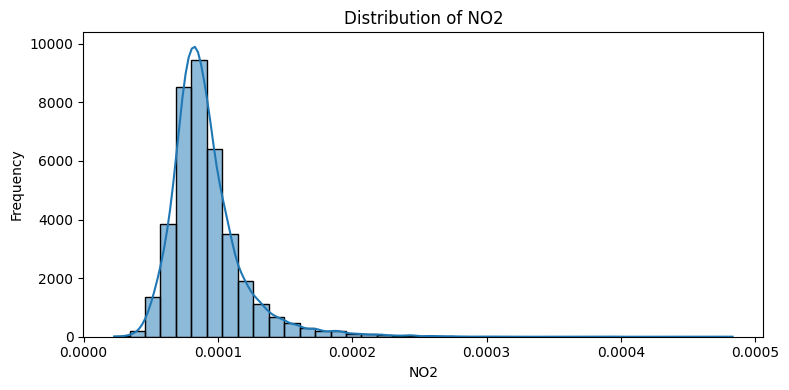

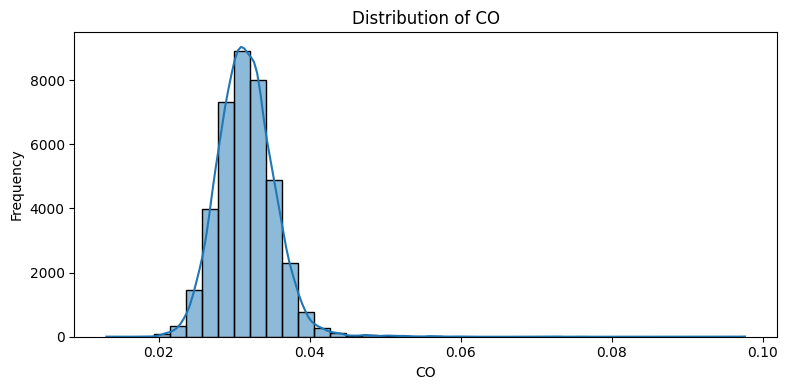

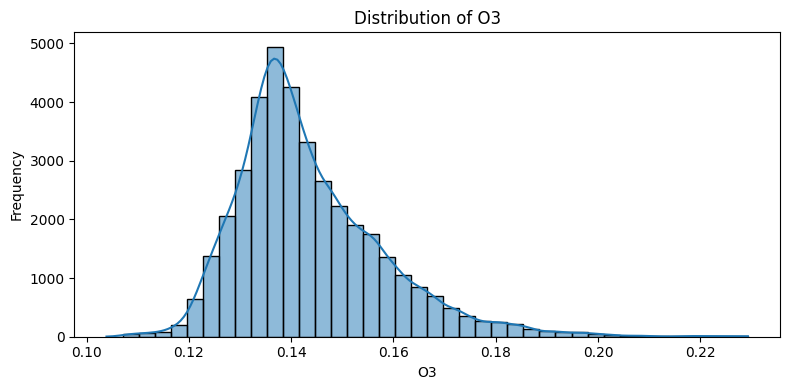


4. BOXPLOTS


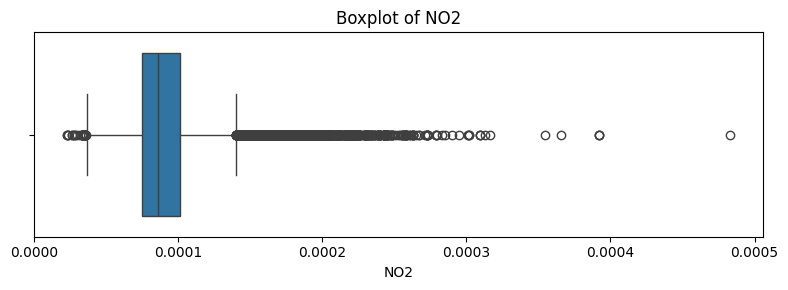

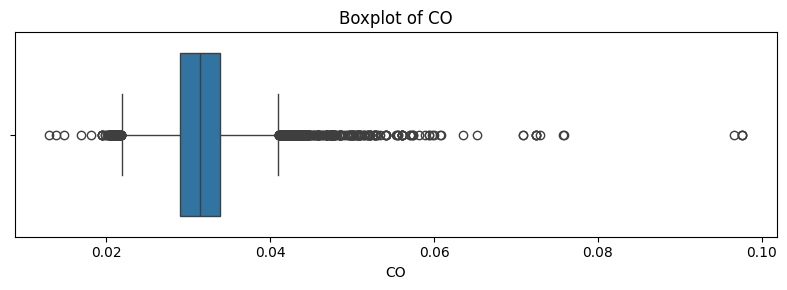

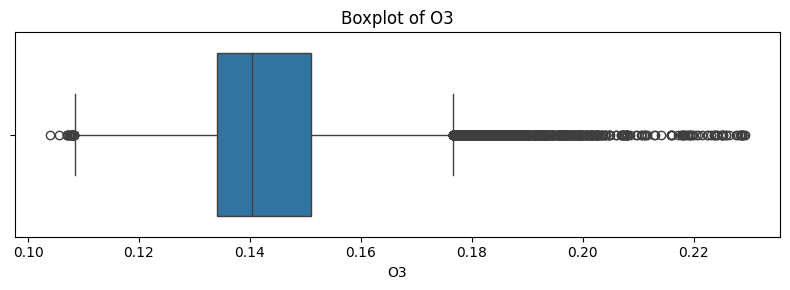


STEP 6 COMPLETED - NO DATA MODIFIED


In [ ]:

# ============================================================
# PART 1 – DATASET AUDIT & DATA CLEANING
# STEP 6 – DISTRIBUTION ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

environmental_vars = ["NO2", "CO", "O3"]


# 1. DESCRIPTIVE STATISTICS
print("1. DESCRIPTIVE STATISTICS")

display(
    df_clean[environmental_vars].describe().T
)


# 2. MEAN VS MEDIAN
print("\n2. MEAN VS MEDIAN")

distribution_stats = pd.DataFrame({
    "Mean": df_clean[environmental_vars].mean(),
    "Median": df_clean[environmental_vars].median(),
    "Std": df_clean[environmental_vars].std(),
    "Skewness": df_clean[environmental_vars].skew()
})

display(distribution_stats)


# 3. HISTOGRAMS
print("\n3. HISTOGRAMS")

for col in environmental_vars:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_clean,
        x=col,
        bins=40,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# 4. BOXPLOTS
print("\n4. BOXPLOTS")

for col in environmental_vars:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df_clean[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


print("\nSTEP 6 COMPLETED - NO DATA MODIFIED")


In [ ]:

# STEP 7.1 - Missing values by station

missing_by_station = df_clean.groupby("sensor_name")[
    ["NO2", "CO", "O3"]
].apply(lambda group: group.isna().sum())

total_by_station = df_clean.groupby("sensor_name").size()

missing_percentage = missing_by_station.div(
    total_by_station, axis=0
) * 100

print("NUMBER OF MISSING VALUES BY STATION")
display(missing_by_station)

print("PERCENTAGE OF MISSING VALUES BY STATION")
display(missing_percentage.round(2))


NUMBER OF MISSING VALUES BY STATION


,NO2,CO,O3
sensor_name,,,
AIX CENTRE ECOLE ART,0,0,0
AIX ROY RENE,0,0,0
ALBALAT DELS TARONGERS,159,159,160
ALCANTARILLA,0,0,0
ALCORA,155,155,158
...,...,...,...
VILAMARXANT,2,2,2
VILLENA PARQUE FERIA,0,0,0
Vila-seca,0,0,0


PERCENTAGE OF MISSING VALUES BY STATION


,NO2,CO,O3
sensor_name,,,
AIX CENTRE ECOLE ART,0.00,0.00,0.00
AIX ROY RENE,0.00,0.00,0.00
ALBALAT DELS TARONGERS,19.92,19.92,20.05
ALCANTARILLA,0.00,0.00,0.00
ALCORA,20.37,20.37,20.76
...,...,...,...
VILAMARXANT,0.58,0.58,0.58
VILLENA PARQUE FERIA,0.00,0.00,0.00
Vila-seca,0.00,0.00,0.00


In [ ]:

# STEP 7.2 - Missing values by year

df_clean["year"] = pd.to_datetime(df_clean["date"]).dt.year

missing_by_year = df_clean.groupby("year")[
    ["NO2", "CO", "O3"]
].apply(lambda group: group.isna().sum())

total_by_year = df_clean.groupby("year").size()

missing_percentage_year = (
    missing_by_year.div(total_by_year, axis=0) * 100
)

print("NUMBER OF MISSING VALUES BY YEAR")
display(missing_by_year)

print("PERCENTAGE OF MISSING VALUES BY YEAR")
display(missing_percentage_year.round(2))


NUMBER OF MISSING VALUES BY YEAR


,NO2,CO,O3
year,,,
2016,111,111,111
2017,2116,2116,2116
2018,180,180,221
2019,0,0,0
2020,0,0,0
2021,0,0,0
2022,0,0,0
2023,0,0,0
2024,0,0,0


PERCENTAGE OF MISSING VALUES BY YEAR


,NO2,CO,O3
year,,,
2016,100.00,100.00,100.0
2017,100.00,100.00,100.0
2018,71.43,71.43,87.7
2019,0.00,0.00,0.0
2020,0.00,0.00,0.0
2021,0.00,0.00,0.0
2022,0.00,0.00,0.0
2023,0.00,0.00,0.0
2024,0.00,0.00,0.0


In [ ]:

# STEP 7.3 - Total and available observations by year

yearly_summary = df_clean.groupby("year").agg(
    Total_Observations=("pm25", "size"),
    NO2_Available=("NO2", "count"),
    CO_Available=("CO", "count"),
    O3_Available=("O3", "count")
)

yearly_summary["NO2_Missing"] = (
    yearly_summary["Total_Observations"] -
    yearly_summary["NO2_Available"]
)

yearly_summary["CO_Missing"] = (
    yearly_summary["Total_Observations"] -
    yearly_summary["CO_Available"]
)

yearly_summary["O3_Missing"] = (
    yearly_summary["Total_Observations"] -
    yearly_summary["O3_Available"]
)

display(yearly_summary)


,Total_Observations,NO2_Available,CO_Available,O3_Available,NO2_Missing,CO_Missing,O3_Missing
year,,,,,,,
2016,111,0,0,0,111,111,111
2017,2116,0,0,0,2116,2116,2116
2018,252,72,72,31,180,180,221
2019,1772,1772,1772,1772,0,0,0
2020,3247,3247,3247,3247,0,0,0
2021,4746,4746,4746,4746,0,0,0
2022,4954,4954,4954,4954,0,0,0
2023,5400,5400,5400,5400,0,0,0
2024,8688,8688,8688,8688,0,0,0


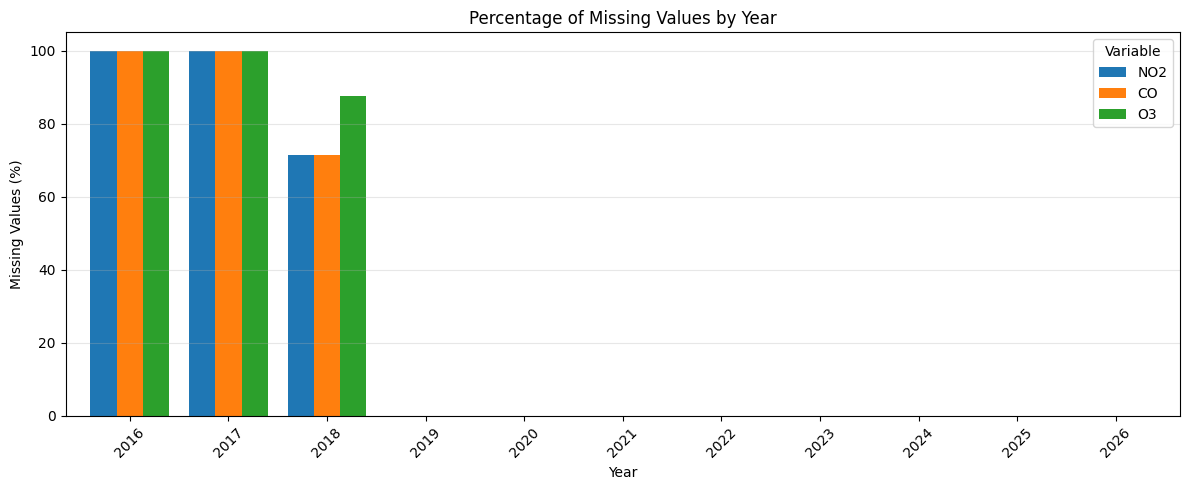

STEP 7.4 COMPLETED - NO DATA MODIFIED


In [ ]:

# STEP 7.4 - Visualize missing values by year

import matplotlib.pyplot as plt

missing_percentage_year.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("Percentage of Missing Values by Year")
plt.xlabel("Year")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.legend(title="Variable")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("STEP 7.4 COMPLETED - NO DATA MODIFIED")


In [ ]:

# STEP 7.5 - Missing values by station and year

missing_station_year = df_clean.groupby(
    ["sensor_name", "year"]
)[["NO2", "CO", "O3"]].apply(
    lambda group: group.isna().sum()
)

print("MISSING VALUES BY STATION AND YEAR")
display(missing_station_year)


MISSING VALUES BY STATION AND YEAR


NO2  CO  O3
sensor_name          year             
AIX CENTRE ECOLE ART 2024    0   0   0
                     2025    0   0   0
                     2026    0   0   0
AIX ROY RENE         2025    0   0   0
                     2026    0   0   0
...                        ...  ..  ..
Vila-seca            2026    0   0   0
Viladecavalls        2025    0   0   0
                     2026    0   0   0
outdoors             2025    0   0   0
                     2026    0   0   0

[358 rows x 3 columns]

In [ ]:

# =====================================================
# STEP 8 - EVALUATION OF MISSING VALUES STRATEGIES
# =====================================================

# 1. Define the three scenarios
scenarios = {
    "Scenario A - 2016 to 2026": df_clean,
    "Scenario B - 2018 to 2026": df_clean[df_clean["year"] >= 2018],
    "Scenario C - 2019 to 2026": df_clean[df_clean["year"] >= 2019]
}

results = []

# 2. Compare the scenarios
for scenario_name, data in scenarios.items():

    total_rows = len(data)

    complete_environmental = data[
        ["NO2", "CO", "O3"]
    ].notna().all(axis=1).sum()

    results.append({
        "Scenario": scenario_name,
        "Total_Observations": total_rows,
        "PM25_Available": data["pm25"].notna().sum(),
        "NO2_Missing": data["NO2"].isna().sum(),
        "CO_Missing": data["CO"].isna().sum(),
        "O3_Missing": data["O3"].isna().sum(),
        "Complete_Environmental_Rows": complete_environmental,
        "Complete_Rows_Percentage": round(
            complete_environmental / total_rows * 100, 2
        )
    })

# 3. Display comparison table
scenario_comparison = pd.DataFrame(results)

print("STEP 8.1 - COMPARISON OF CLEANING SCENARIOS")
display(scenario_comparison)

# 4. Calculate retained observations
print("OBSERVATIONS RETAINED COMPARED TO ORIGINAL CLEAN DATASET")

for scenario_name, data in scenarios.items():

    retained_percentage = len(data) / len(df_clean) * 100

    print(
        f"{scenario_name}: "
        f"{len(data)} observations "
        f"({retained_percentage:.2f}% retained)"
    )

print("STEP 8.1 COMPLETED - NO DATA MODIFIED")


STEP 8.1 - COMPARISON OF CLEANING SCENARIOS


,Scenario,Total_Observations,PM25_Available,NO2_Missing,CO_Missing,O3_Missing,Complete_Environmental_Rows,Complete_Rows_Percentage
0,Scenario A - 2016 to 2026,40983,40983,2407,2407,2448,38535,94.03
1,Scenario B - 2018 to 2026,38756,38756,180,180,221,38535,99.43
2,Scenario C - 2019 to 2026,38504,38504,0,0,0,38504,100.00


OBSERVATIONS RETAINED COMPARED TO ORIGINAL CLEAN DATASET
Scenario A - 2016 to 2026: 40983 observations (100.00% retained)
Scenario B - 2018 to 2026: 38756 observations (94.57% retained)
Scenario C - 2019 to 2026: 38504 observations (93.95% retained)
STEP 8.1 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 8.2 - ANALYSIS OF INCOMPLETE ROWS IN 2018
# =====================================================

# Select 2018 observations
df_2018 = df_clean[df_clean["year"] == 2018].copy()

environmental_vars = ["NO2", "CO", "O3"]

# Missingness patterns
missing_patterns = (
    df_2018[environmental_vars]
    .isna()
    .value_counts()
    .reset_index(name="Number_of_Rows")
)

print("MISSINGNESS PATTERNS IN 2018")
display(missing_patterns)

# Count rows by missingness situation
total_2018 = len(df_2018)

all_missing = df_2018[environmental_vars].isna().all(axis=1).sum()

all_available = df_2018[environmental_vars].notna().all(axis=1).sum()

partially_missing = (
    df_2018[environmental_vars].isna().any(axis=1) &
    df_2018[environmental_vars].notna().any(axis=1)
).sum()

print("SUMMARY OF 2018")
print("Total observations:", total_2018)
print("All environmental variables missing:", all_missing)
print("All environmental variables available:", all_available)
print("Partially missing rows:", partially_missing)

print("STEP 8.2 COMPLETED - NO DATA MODIFIED")


MISSINGNESS PATTERNS IN 2018


,NO2,CO,O3,Number_of_Rows
0,True,True,True,180
1,False,False,True,41
2,False,False,False,31


SUMMARY OF 2018
Total observations: 252
All environmental variables missing: 180
All environmental variables available: 31
Partially missing rows: 41
STEP 8.2 COMPLETED - NO DATA MODIFIED


MISSING OBSERVATIONS BY MONTH IN 2018


,month,Missing_Observations
0,1,103
1,3,9
2,5,13
3,6,32
4,8,9
5,9,14


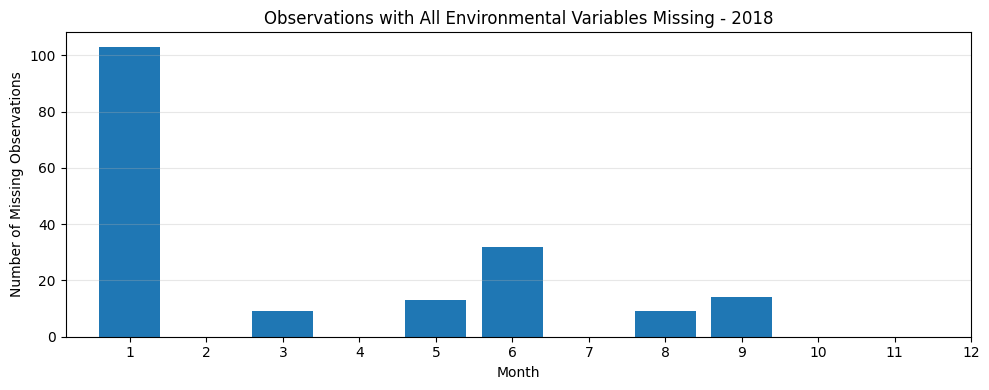

STEP 8.3 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 8.3 - TEMPORAL DISTRIBUTION OF MISSING VALUES
# =====================================================

# Select 2018 observations where all environmental
# variables are missing
missing_2018 = df_clean[
    (df_clean["year"] == 2018) &
    (df_clean[["NO2", "CO", "O3"]].isna().all(axis=1))
].copy()

# Extract month
missing_2018["month"] = pd.to_datetime(
    missing_2018["date"]
).dt.month

# Count missing observations by month
missing_by_month = (
    missing_2018.groupby("month")
    .size()
    .reset_index(name="Missing_Observations")
)

print("MISSING OBSERVATIONS BY MONTH IN 2018")
display(missing_by_month)

# Visualize the distribution
plt.figure(figsize=(10, 4))

plt.bar(
    missing_by_month["month"],
    missing_by_month["Missing_Observations"]
)

plt.title("Observations with All Environmental Variables Missing - 2018")
plt.xlabel("Month")
plt.ylabel("Number of Missing Observations")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("STEP 8.3 COMPLETED - NO DATA MODIFIED")


In [ ]:

# =====================================================
# STEP 8.4 - MISSING VALUES BY STATION AND MONTH (2018)
# =====================================================

# Select 2018 observations
df_2018 = df_clean[df_clean["year"] == 2018].copy()

# Extract month
df_2018["month"] = pd.to_datetime(
    df_2018["date"]
).dt.month

# Identify rows where all environmental variables are missing
df_2018["All_Environmental_Missing"] = (
    df_2018[["NO2", "CO", "O3"]].isna().all(axis=1)
)

# Count missing observations by station and month
missing_station_month = (
    df_2018[df_2018["All_Environmental_Missing"]]
    .groupby(["sensor_name", "month"])
    .size()
    .reset_index(name="Missing_Observations")
    .sort_values("Missing_Observations", ascending=False)
)

print("MISSING OBSERVATIONS BY STATION AND MONTH - 2018")
display(missing_station_month)

# Top 10 stations with the most missing observations
print("TOP 10 STATIONS WITH THE MOST MISSING OBSERVATIONS")

top_stations = (
    missing_station_month.groupby("sensor_name")[
        "Missing_Observations"
    ].sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_stations)

print("STEP 8.4 COMPLETED - NO DATA MODIFIED")


MISSING OBSERVATIONS BY STATION AND MONTH - 2018


,sensor_name,month,Missing_Observations
4,ALCORA,1,7
12,ALMASSORA-C. P. OCHANDO,1,7
54,QUART DE POBLET,1,7
67,VALÈNCIA-PISTA DE SILLA,1,7
23,ELDA-LACY,1,7
...,...,...,...
64,VALÈNCIA - AVD. FRANCIA,5,1
73,VALÈNCIA-POLITÈCNIC,3,1
71,VALÈNCIA-PISTA DE SILLA,9,1
74,VALÈNCIA-POLITÈCNIC,5,1


TOP 10 STATIONS WITH THE MOST MISSING OBSERVATIONS


,Missing_Observations
sensor_name,
QUART DE POBLET,13
ELDA-LACY,13
VALÈNCIA-PISTA DE SILLA,12
VALÈNCIA-POLITÈCNIC,12
FR03029,12
FR03006,12
FR03043,11
ALCORA,11
ALMASSORA-C. P. OCHANDO,11


STEP 8.4 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 8.5 - MISSING VALUE PERCENTAGE BY STATION AND MONTH
# =====================================================

# Select 2018 observations
df_2018 = df_clean[df_clean["year"] == 2018].copy()

# Extract month
df_2018["month"] = pd.to_datetime(
    df_2018["date"]
).dt.month

environmental_vars = ["NO2", "CO", "O3"]

# Total observations per station and month
total_station_month = (
    df_2018.groupby(["sensor_name", "month"])
    .size()
    .reset_index(name="Total_Observations")
)

# Missing observations per station and month
missing_station_month = (
    df_2018.groupby(["sensor_name", "month"])[environmental_vars]
    .apply(lambda group: group.isna().sum())
    .reset_index()
)

# Merge total and missing observations
station_month_analysis = total_station_month.merge(
    missing_station_month,
    on=["sensor_name", "month"]
)

# Calculate missing percentages
for variable in environmental_vars:
    station_month_analysis[f"{variable}_Missing_Percentage"] = (
        station_month_analysis[variable] /
        station_month_analysis["Total_Observations"] * 100
    ).round(2)

# Display station-month combinations with missing values
station_month_analysis = station_month_analysis[
    (station_month_analysis[environmental_vars] > 0).any(axis=1)
].sort_values(
    by="NO2_Missing_Percentage",
    ascending=False
)

print("MISSING VALUE PERCENTAGES BY STATION AND MONTH - 2018")
display(station_month_analysis)

print("STEP 8.5 COMPLETED - NO DATA MODIFIED")


MISSING VALUE PERCENTAGES BY STATION AND MONTH - 2018


,sensor_name,month,Total_Observations,NO2,CO,O3,NO2_Missing_Percentage,CO_Missing_Percentage,O3_Missing_Percentage
0,ALBALAT DELS TARONGERS,1,6,6,6,6,100.0,100.0,100.0
1,ALBALAT DELS TARONGERS,6,2,2,2,2,100.0,100.0,100.0
2,ALBALAT DELS TARONGERS,8,1,1,1,1,100.0,100.0,100.0
6,ALCORA,1,7,7,7,7,100.0,100.0,100.0
7,ALCORA,5,1,1,1,1,100.0,100.0,100.0
...,...,...,...,...,...,...,...,...,...
94,VALÈNCIA - AVD. FRANCIA,9,4,1,1,4,25.0,25.0,100.0
107,VALÈNCIA-POLITÈCNIC,9,4,1,1,4,25.0,25.0,100.0
75,ONTINYENT,9,2,0,0,2,0.0,0.0,100.0
69,FR03043,9,2,0,0,2,0.0,0.0,100.0


STEP 8.5 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 8.6 - DATA AVAILABILITY BY STATION IN 2018
# =====================================================

# Select 2018 observations
df_2018 = df_clean[df_clean["year"] == 2018].copy()

environmental_vars = ["NO2", "CO", "O3"]

# Count total and available observations by station
station_availability = df_2018.groupby("sensor_name").agg(
    Total_Observations=("pm25", "size"),
    NO2_Available=("NO2", "count"),
    CO_Available=("CO", "count"),
    O3_Available=("O3", "count")
)

# Calculate availability percentages
for variable in environmental_vars:
    station_availability[f"{variable}_Availability_Percentage"] = (
        station_availability[f"{variable}_Available"] /
        station_availability["Total_Observations"] * 100
    ).round(2)

# Sort stations by total observations
station_availability = station_availability.sort_values(
    "Total_Observations",
    ascending=False
)

print("DATA AVAILABILITY BY STATION - 2018")
display(station_availability)

print("STEP 8.6 COMPLETED - NO DATA MODIFIED")


DATA AVAILABILITY BY STATION - 2018


,Total_Observations,NO2_Available,CO_Available,O3_Available,NO2_Availability_Percentage,CO_Availability_Percentage,O3_Availability_Percentage
sensor_name,,,,,,,
QUART DE POBLET,18,5,5,2,27.78,27.78,11.11
ELDA-LACY,18,5,5,2,27.78,27.78,11.11
VALÈNCIA-POLITÈCNIC,17,5,5,2,29.41,29.41,11.76
BENICASSIM,16,6,6,3,37.50,37.50,18.75
VALÈNCIA-PISTA DE SILLA,16,4,4,1,25.00,25.00,6.25
ALCORA,15,4,4,1,26.67,26.67,6.67
SAGUNT CEA,15,5,5,2,33.33,33.33,13.33
FR03029,15,3,3,1,20.00,20.00,6.67
BURRIANA,15,5,5,2,33.33,33.33,13.33


STEP 8.6 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 9 - DUPLICATES AND TEMPORAL CONSISTENCY
# =====================================================

# 9.1 - Complete duplicate rows
print("1. COMPLETE DUPLICATE ROWS")

complete_duplicates = df_clean.duplicated().sum()
print("Complete duplicates:", complete_duplicates)


# 9.2 - Duplicate station-date combinations
print("\n2. DUPLICATE STATION-DATE RECORDS")

duplicate_station_date = df_clean.duplicated(
    subset=["sensor_name", "date"]
).sum()

print("Duplicate station-date records:", duplicate_station_date)


# 9.3 - Invalid dates
print("\n3. INVALID DATES")

parsed_dates = pd.to_datetime(
    df_clean["date"],
    errors="coerce"
)

invalid_dates = parsed_dates.isna().sum()

print("Invalid dates:", invalid_dates)


# 9.4 - Chronological order
print("\n4. CHRONOLOGICAL ORDER")

is_sorted = parsed_dates.is_monotonic_increasing

print("Dataset chronologically sorted:", is_sorted)


# 9.5 - Time intervals by station
print("\n5. TIME INTERVALS BETWEEN OBSERVATIONS")

temporal_check = df_clean.copy()

temporal_check["parsed_date"] = parsed_dates

temporal_check = temporal_check.sort_values(
    ["sensor_name", "parsed_date"]
)

temporal_check["days_between_observations"] = (
    temporal_check.groupby("sensor_name")["parsed_date"]
    .diff()
    .dt.days
)

print("Days between observations - descriptive statistics")

display(
    temporal_check["days_between_observations"].describe()
)

print("\nSTEP 9 COMPLETED - NO DATA MODIFIED")


1. COMPLETE DUPLICATE ROWS
Complete duplicates: 0

2. DUPLICATE STATION-DATE RECORDS
Duplicate station-date records: 2

3. INVALID DATES
Invalid dates: 0

4. CHRONOLOGICAL ORDER
Dataset chronologically sorted: True

5. TIME INTERVALS BETWEEN OBSERVATIONS
Days between observations - descriptive statistics


,days_between_observations
count,40892.000000
mean,2.334246
std,14.288934
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,2383.000000



STEP 9 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 9.1 - INVESTIGATE DUPLICATE STATION-DATE RECORDS
# =====================================================

duplicate_records = df_clean[
    df_clean.duplicated(
        subset=["sensor_name", "date"],
        keep=False
    )
].sort_values(["sensor_name", "date", "datetime_utc"])

print("DUPLICATE STATION-DATE RECORDS")
print("Number of rows involved:", len(duplicate_records))

display(duplicate_records)

print("STEP 9.1 COMPLETED - NO DATA MODIFIED")


DUPLICATE STATION-DATE RECORDS
Number of rows involved: 4


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name,year
29054,2024-08-30,2024-08-30,105,38.057300,-1.204700,24.053120,991.021203,-0.206704,-0.795269,0.000083,0.033897,0.143295,0.218,11.665,MOLINA DE SEGURA,2024
29055,2024-08-30,2024-08-30,107,38.057373,-1.204813,24.053120,991.021203,-0.206704,-0.795269,0.000083,0.033897,0.143295,0.218,10.530,MOLINA DE SEGURA,2024
29052,2024-08-30,2024-08-30,109,37.992300,-1.145900,24.680073,997.004953,-0.606647,-1.348858,0.000075,0.035093,0.143506,0.228,11.680,SAN BASILIO,2024
29053,2024-08-30,2024-08-30,104,37.993611,-1.144722,24.680073,997.004953,-0.606647,-1.348858,0.000075,0.035093,0.143506,0.228,13.235,SAN BASILIO,2024


STEP 9.1 COMPLETED - NO DATA MODIFIED


In [ ]:

# STEP 9.2 - FINAL CHECK OF LONG TEMPORAL GAPS

long_gaps = temporal_check[
    temporal_check["days_between_observations"] > 30
].copy()

long_gaps = long_gaps.sort_values(
    "days_between_observations",
    ascending=False
)

print("Number of gaps greater than 30 days:", len(long_gaps))

print("TOP 20 LONGEST GAPS")

display(
    long_gaps[
        [
            "sensor_name",
            "date",
            "days_between_observations"
        ]
    ].head(20)
)

print("GAPS BY STATION")

display(
    long_gaps.groupby("sensor_name")
    .agg(
        Number_of_Long_Gaps=("days_between_observations", "count"),
        Maximum_Gap_Days=("days_between_observations", "max")
    )
    .sort_values("Maximum_Gap_Days", ascending=False)
    .head(20)
)

print("STEP 9.2 COMPLETED - NO DATA MODIFIED")


Number of gaps greater than 30 days: 213
TOP 20 LONGEST GAPS


,sensor_name,date,days_between_observations
23412,VALÈNCIA - MOLÍ DEL SOL,2024-01-28,2383.0
33314,Sant Andreu de la Barca,2025-03-15,591.0
18305,"C. Restoy, 51, Almeria, Spain",2023-05-07,433.0
37437,La Sagrera,2025-08-21,419.0
2486,VILAMARXANT,2019-01-02,344.0
34482,ONTINYENT,2025-05-13,315.0
21210,MOMPEAN,2023-09-28,298.0
35169,VILAMARXANT,2025-06-04,268.0
7928,VILAMARXANT,2021-01-05,203.0
4628,VILAMARXANT,2020-01-06,184.0


GAPS BY STATION


,Number_of_Long_Gaps,Maximum_Gap_Days
sensor_name,,
VALÈNCIA - MOLÍ DEL SOL,2,2383.0
Sant Andreu de la Barca,1,591.0
"C. Restoy, 51, Almeria, Spain",1,433.0
La Sagrera,1,419.0
VILAMARXANT,20,344.0
ONTINYENT,28,315.0
MOMPEAN,1,298.0
ALGAR DE PALÀNCIA,7,175.0
ALBALAT DELS TARONGERS,7,151.0


STEP 9.2 COMPLETED - NO DATA MODIFIED


In [ ]:

# =====================================================
# STEP 10 - FINAL DATASET PREPARATION
# DATASET AUDIT & DATA CLEANING
# =====================================================

# 1. Create a copy of the cleaned dataset
df_final_pm25 = df_clean.copy()

# 2. Create a multivariate dataset with complete
# environmental variables (2019-2026)
df_final_multivariate = df_clean[
    (df_clean["year"] >= 2019)
].copy()

# 3. Define environmental variables
environmental_vars = ["NO2", "CO", "O3"]

# 4. Verify the datasets
print("FINAL PM2.5 DATASET")
print("Rows:", len(df_final_pm25))
print("Columns:", len(df_final_pm25.columns))
print("Period:",
      df_final_pm25["date"].min(),
      "to",
      df_final_pm25["date"].max())

print("\nFINAL MULTIVARIATE DATASET")
print("Rows:", len(df_final_multivariate))
print("Columns:", len(df_final_multivariate.columns))
print("Period:",
      df_final_multivariate["date"].min(),
      "to",
      df_final_multivariate["date"].max())

# 5. Verify missing values
print("\nMISSING VALUES - PM2.5 DATASET")
display(df_final_pm25.isna().sum())

print("\nMISSING VALUES - MULTIVARIATE DATASET")
display(df_final_multivariate.isna().sum())

# 6. Verify PM2.5 validity
print("\nPM2.5 VALIDATION")

print("PM2.5 missing:",
      df_final_pm25["pm25"].isna().sum())

print("PM2.5 <= 0:",
      (df_final_pm25["pm25"] <= 0).sum())

print("PM2.5 >= 500:",
      (df_final_pm25["pm25"] >= 500).sum())

print("\nSTEP 10.1 COMPLETED - DATASETS CREATED")


FINAL PM2.5 DATASET
Rows: 40983
Columns: 16
Period: 2016-11-25 00:00:00 to 2026-04-06 00:00:00

FINAL MULTIVARIATE DATASET
Rows: 38504
Columns: 16
Period: 2019-01-02 00:00:00 to 2026-04-06 00:00:00

MISSING VALUES - PM2.5 DATASET


,0
date,0
datetime_utc,0
id,0
latitude,0
longitude,0
temperature_celsius,0
pressure_mb,0
wind_u,0
wind_v,0
NO2,2407



MISSING VALUES - MULTIVARIATE DATASET


,0
date,0
datetime_utc,0
id,0
latitude,0
longitude,0
temperature_celsius,0
pressure_mb,0
wind_u,0
wind_v,0
NO2,0



PM2.5 VALIDATION
PM2.5 missing: 0
PM2.5 <= 0: 0
PM2.5 >= 500: 0

STEP 10.1 COMPLETED - DATASETS CREATED


In [ ]:
# Créer une copie de travail
df_preprocessing = df_final_pm25.copy()

# Créer un indicateur pour chaque variable
for col in ["NO2", "CO", "O3"]:
    df_preprocessing[f"{col}_missing"] = (
        df_preprocessing[col].isna().astype(int)
    )

# Vérifier les indicateurs
for col in ["NO2", "CO", "O3"]:
    print(f"\n{col}_missing :")
    print(df_preprocessing[f"{col}_missing"].value_counts())

print("\nDimensions :", df_preprocessing.shape)


NO2_missing :
NO2_missing
0    38576
1     2407
Name: count, dtype: int64

CO_missing :
CO_missing
0    38576
1     2407
Name: count, dtype: int64

O3_missing :
O3_missing
0    38535
1     2448
Name: count, dtype: int64

Dimensions : (40983, 19)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Variables environnementales
environmental_cols = ["NO2", "CO", "O3"]

# Pipeline d'imputation
imputation_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Vérifier la configuration
print("Méthode :", imputation_pipeline.named_steps["imputer"].strategy)
print("Variables concernées :", environmental_cols)
print("Indicateurs créés :", [
    "NO2_missing", "CO_missing", "O3_missing"
])

Méthode : median
Variables concernées : ['NO2', 'CO', 'O3']
Indicateurs créés : ['NO2_missing', 'CO_missing', 'O3_missing']


In [ ]:

# Validation des valeurs manquantes et des indicateurs
# Aucune imputation n'est effectuée à cette étape.

environmental_cols = ["NO2", "CO", "O3"]
missing_indicator_cols = [
    "NO2_missing",
    "CO_missing",
    "O3_missing"
]

print("Valeurs manquantes dans le dataset de référence :")
print(df_final_pm25[environmental_cols].isna().sum())

print("\nNombre de valeurs manquantes détectées par les indicateurs :")
print(df_preprocessing[missing_indicator_cols].sum())

print("\nVérification de la cohérence des indicateurs :")
for col in environmental_cols:
    indicator = f"{col}_missing"
    consistent = (
        df_preprocessing[indicator].eq(
            df_preprocessing[col].isna().astype(int)
        )
    ).all()
    print(f"{indicator}: {consistent}")

print("\nDimensions du dataset de référence :", df_final_pm25.shape)
print("Dimensions du dataset de preprocessing :", df_preprocessing.shape)

print("\nAucune imputation globale effectuée.")


Valeurs manquantes dans le dataset de référence :
NO2    2407
CO     2407
O3     2448
dtype: int64

Nombre de valeurs manquantes détectées par les indicateurs :
NO2_missing    2407
CO_missing     2407
O3_missing     2448
dtype: int64

Vérification de la cohérence des indicateurs :
NO2_missing: True
CO_missing: True
O3_missing: True

Dimensions du dataset de référence : (40983, 16)
Dimensions du dataset de preprocessing : (40983, 19)

Aucune imputation globale effectuée.


In [ ]:
import pandas as pd

# Sélectionner les variables numériques
numeric_cols = df_final_pm25.select_dtypes(
    include="number"
).columns

# Calculer les statistiques descriptives
exploratory_summary = df_final_pm25[numeric_cols].describe().T

# Ajouter les statistiques demandées
exploratory_summary["missing"] = (
    df_final_pm25[numeric_cols].isnull().sum()
)

exploratory_summary["pct_missing"] = (
    df_final_pm25[numeric_cols].isnull().mean() * 100
)

exploratory_summary["skewness"] = (
    df_final_pm25[numeric_cols].skew()
)

exploratory_summary["kurtosis"] = (
    df_final_pm25[numeric_cols].kurtosis()
)

# Afficher le tableau
display(exploratory_summary.round(4))

,count,mean,std,min,25%,50%,75%,max,missing,pct_missing,skewness,kurtosis
id,40983.0,52.7250,35.0340,0.0000,21.0000,50.0000,90.0000,109.0000,0,0.0000,0.1027,-1.5133
latitude,40983.0,39.0304,2.2311,36.1333,36.8413,39.4483,40.0519,43.5303,0,0.0000,0.3970,-0.6863
longitude,40983.0,-0.4664,3.8291,-5.6635,-3.6127,-0.4060,1.1496,9.1364,0,0.0000,0.6438,0.1583
temperature_celsius,40983.0,18.2720,6.3862,-1.2791,12.9657,18.4947,23.7879,34.8658,0,0.0000,-0.1023,-0.9712
pressure_mb,40983.0,993.8174,17.1800,930.3171,987.9864,997.7287,1005.3668,1033.6622,0,0.0000,-1.0869,0.7143
wind_u,40983.0,0.3434,2.5278,-11.0987,-0.9848,0.2058,1.6842,9.6617,0,0.0000,-0.1778,1.0342
wind_v,40983.0,-0.1788,1.3856,-10.8600,-0.7309,0.0427,0.6615,8.4864,0,0.0000,-1.2766,4.3890
NO2,38576.0,0.0001,0.0000,0.0000,0.0001,0.0001,0.0001,0.0005,2407,5.8732,2.1227,9.1775
CO,38576.0,0.0316,0.0039,0.0131,0.0290,0.0314,0.0338,0.0976,2407,5.8732,1.3982,13.7684
O3,38535.0,0.1435,0.0145,0.1039,0.1340,0.1405,0.1510,0.2293,2448,5.9732,1.1505,2.2781


In [ ]:
# Vérification des types et des unités disponibles
print("TYPES DES VARIABLES")
print(df_final_pm25.dtypes)

print("\nEXEMPLES DE DONNÉES")
display(df_final_pm25.head())

print("\nNOMBRE DE STATIONS")
print(df_final_pm25["sensor_name"].nunique())

print("\nNOMBRE D'IDENTIFIANTS")
print(df_final_pm25["id"].nunique())

TYPES DES VARIABLES
date                   datetime64[ns]
datetime_utc           datetime64[ns]
id                              int64
latitude                      float64
longitude                     float64
temperature_celsius           float64
pressure_mb                   float64
wind_u                        float64
wind_v                        float64
NO2                           float64
CO                            float64
O3                            float64
AOD                           float64
pm25                          float64
sensor_name                    object
year                            int32
dtype: object

EXEMPLES DE DONNÉES


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name,year
0,2016-11-25,2016-11-25,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT,2016
1,2016-11-25,2016-11-25,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO,2016
2,2016-11-30,2016-11-30,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA,2016
3,2016-11-30,2016-11-30,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM,2016
4,2016-12-02,2016-12-02,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT,2016



NOMBRE DE STATIONS
91

NOMBRE D'IDENTIFIANTS
95


In [ ]:
# Vérifier les différences entre date et datetime_utc

print("Dates différentes :",
      (df_final_pm25["date"].dt.date !=
       df_final_pm25["datetime_utc"].dt.date).sum())

print("\nIDs associés à plusieurs stations :")
stations_per_id = df_final_pm25.groupby("id")["sensor_name"].nunique()
print(stations_per_id[stations_per_id > 1])

print("\nStations associées à plusieurs IDs :")
ids_per_station = df_final_pm25.groupby("sensor_name")["id"].nunique()
print(ids_per_station[ids_per_station > 1])

Dates différentes : 0

IDs associés à plusieurs stations :
Series([], Name: sensor_name, dtype: int64)

Stations associées à plusieurs IDs :
sensor_name
LA ALJORRA          2
MOLINA DE SEGURA    2
MOMPEAN             2
SAN BASILIO         2
Name: id, dtype: int64


In [ ]:
# Vérifier les unités et les plages des variables

columns_to_check = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD",
    "pm25"
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Minimum :", df_final_pm25[col].min())
    print("Maximum :", df_final_pm25[col].max())
    print("Médiane :", df_final_pm25[col].median())


--- temperature_celsius ---
Minimum : -1.2790531158447038
Maximum : 34.86583099365237
Médiane : 18.494734064738

--- pressure_mb ---
Minimum : 930.3170654296875
Maximum : 1033.6621761067709
Médiane : 997.7287158203123

--- wind_u ---
Minimum : -11.09872309366862
Maximum : 9.661650975545248
Médiane : 0.2058461507161458

--- wind_v ---
Minimum : -10.860048135121664
Maximum : 8.486382762591044
Médiane : 0.0427302519480387

--- NO2 ---
Minimum : 2.268400037853421e-05
Maximum : 0.0004831401596448
Médiane : 8.632243515503869e-05

--- CO ---
Minimum : 0.0130575448112163
Maximum : 0.0976130890603928
Médiane : 0.031411616713917

--- O3 ---
Minimum : 0.1038994989882649
Maximum : 0.229321851252819
Médiane : 0.1404717151800516

--- AOD ---
Minimum : 0.0
Maximum : 5.4750000000000005
Médiane : 0.128

--- pm25 ---
Minimum : 0.0066666666666666
Maximum : 484.9815
Médiane : 7.851176470588236


In [ ]:
# Examiner les 15 valeurs les plus élevées de PM2.5
print("TOP 15 PM2.5")
display(
    df_final_pm25[
        ["date", "sensor_name", "latitude", "longitude", "pm25"]
    ].nlargest(15, "pm25")
)

# Examiner les 15 valeurs les plus élevées de AOD
print("\nTOP 15 AOD")
display(
    df_final_pm25[
        ["date", "sensor_name", "latitude", "longitude", "AOD"]
    ].nlargest(15, "AOD")
)
# Analyse des valeurs extrêmes de PM2.5 et AOD

print("=" * 70)
print("TOP 15 DES VALEURS PM2.5 LES PLUS ÉLEVÉES")
print("=" * 70)

display(
    df_final_pm25[
        ["date", "sensor_name", "latitude", "longitude", "pm25"]
    ].nlargest(15, "pm25").reset_index(drop=True)
)

print("\n" + "=" * 70)
print("TOP 15 DES VALEURS AOD LES PLUS ÉLEVÉES")
print("=" * 70)

display(
    df_final_pm25[
        ["date", "sensor_name", "latitude", "longitude", "AOD"]
    ].nlargest(15, "AOD").reset_index(drop=True)
)

TOP 15 PM2.5


,date,sensor_name,latitude,longitude,pm25
29186,2024-09-04,CENCA1,39.235833,9.115000,484.981500
11856,2021-11-22,LOS BARRIOS,36.175380,-5.480830,483.875000
11413,2021-11-02,HOSTELERÍA,36.203880,-5.383710,445.062500
13078,2022-01-19,LOS BARRIOS,36.175380,-5.480830,399.400000
12773,2022-01-07,HOSTELERÍA,36.203880,-5.383710,373.000000
13777,2022-02-14,GUADARRANQUE,36.182100,-5.411410,338.800000
11533,2021-11-07,CAMPAMENTO,36.179430,-5.376970,315.000000
5312,2020-04-04,ALCORA,40.051944,-0.189722,303.500000
11875,2021-11-23,LOS BARRIOS,36.175380,-5.480830,299.625000
30276,2024-10-17,CENCA1,39.235833,9.115000,295.238050



TOP 15 AOD


,date,sensor_name,latitude,longitude,AOD
15605,2022-07-02,MOMPEAN,37.603056,-0.975278,5.475
8656,2021-03-29,MOMPEAN,37.603056,-0.975278,3.909
30199,2024-10-13,VALLE DE ESCOMBRERAS,37.574400,-0.926543,3.706
26402,2024-06-08,Fos Les Carabins,43.458927,4.934572,2.245
40756,2026-02-05,CENCA1,39.235833,9.115000,2.038
40757,2026-02-05,CENMO1,39.260556,9.136389,2.038
37312,2025-08-17,VILA-SECA (IES VILA-SECA),41.102400,1.149600,1.801
37313,2025-08-17,Vila-seca,41.102505,1.149445,1.801
37314,2025-08-17,Tarragona,41.115910,1.191999,1.801
37315,2025-08-17,Perafort,41.193604,1.236701,1.465


TOP 15 DES VALEURS PM2.5 LES PLUS ÉLEVÉES


,date,sensor_name,latitude,longitude,pm25
0,2024-09-04,CENCA1,39.235833,9.115000,484.981500
1,2021-11-22,LOS BARRIOS,36.175380,-5.480830,483.875000
2,2021-11-02,HOSTELERÍA,36.203880,-5.383710,445.062500
3,2022-01-19,LOS BARRIOS,36.175380,-5.480830,399.400000
4,2022-01-07,HOSTELERÍA,36.203880,-5.383710,373.000000
5,2022-02-14,GUADARRANQUE,36.182100,-5.411410,338.800000
6,2021-11-07,CAMPAMENTO,36.179430,-5.376970,315.000000
7,2020-04-04,ALCORA,40.051944,-0.189722,303.500000
8,2021-11-23,LOS BARRIOS,36.175380,-5.480830,299.625000
9,2024-10-17,CENCA1,39.235833,9.115000,295.238050



TOP 15 DES VALEURS AOD LES PLUS ÉLEVÉES


,date,sensor_name,latitude,longitude,AOD
0,2022-07-02,MOMPEAN,37.603056,-0.975278,5.475
1,2021-03-29,MOMPEAN,37.603056,-0.975278,3.909
2,2024-10-13,VALLE DE ESCOMBRERAS,37.574400,-0.926543,3.706
3,2024-06-08,Fos Les Carabins,43.458927,4.934572,2.245
4,2026-02-05,CENCA1,39.235833,9.115000,2.038
5,2026-02-05,CENMO1,39.260556,9.136389,2.038
6,2025-08-17,VILA-SECA (IES VILA-SECA),41.102400,1.149600,1.801
7,2025-08-17,Vila-seca,41.102505,1.149445,1.801
8,2025-08-17,Tarragona,41.115910,1.191999,1.801
9,2025-08-17,Perafort,41.193604,1.236701,1.465


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from scipy.stats import zscore

# Variables à analyser
variables = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD",
    "pm25"
]

results = []

for col in variables:

    data = df_final_pm25[col].dropna()

    # Méthode IQR
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_outliers = (
        (data < lower_bound) |
        (data > upper_bound)
    ).sum()

    # Méthode Z-score
    z_scores = np.abs(zscore(data))
    z_outliers = (z_scores > 3).sum()

    # Méthode Isolation Forest
    iso = IsolationForest(
        contamination="auto",
        random_state=42
    )

    predictions = iso.fit_predict(data.to_frame())
    if_outliers = (predictions == -1).sum()

    results.append({
        "Variable": col,
        "IQR_Outliers": int(iqr_outliers),
        "IQR_Percentage": round(iqr_outliers / len(data) * 100, 2),
        "Zscore_Outliers": int(z_outliers),
        "Zscore_Percentage": round(z_outliers / len(data) * 100, 2),
        "IsolationForest_Outliers": int(if_outliers),
        "IF_Percentage": round(if_outliers / len(data) * 100, 2)
    })

outliers_summary = pd.DataFrame(results)

display(outliers_summary)

,Variable,IQR_Outliers,IQR_Percentage,Zscore_Outliers,Zscore_Percentage,IsolationForest_Outliers,IF_Percentage
0,temperature_celsius,0,0.00,4,0.01,8248,20.13
1,pressure_mb,3179,7.76,72,0.18,12754,31.12
2,wind_u,2133,5.20,281,0.69,10333,25.21
3,wind_v,2234,5.45,753,1.84,6879,16.79
4,NO2,2061,5.34,731,1.89,9040,23.43
5,CO,572,1.48,257,0.67,6416,16.63
6,O3,1219,3.16,463,1.20,9004,23.37
7,AOD,1114,2.72,299,0.73,8348,20.37
8,pm25,1613,3.94,255,0.62,7815,19.07


In [ ]:
import numpy as np
import pandas as pd

# Détection IQR des valeurs extrêmes de PM2.5
data = df_final_pm25["pm25"]

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identifier les observations extrêmes
df_pm25_outliers = df_final_pm25[
    (df_final_pm25["pm25"] < lower_bound) |
    (df_final_pm25["pm25"] > upper_bound)
].copy()

# Nombre et pourcentage par station
outliers_by_station = (
    df_pm25_outliers.groupby("sensor_name")
    .agg(
        Outliers=("pm25", "count"),
        Mean_PM25=("pm25", "mean"),
        Max_PM25=("pm25", "max")
    )
    .sort_values("Outliers", ascending=False)
)

# Nombre total d'observations par station
total_by_station = (
    df_final_pm25.groupby("sensor_name")
    .size()
    .rename("Total_Observations")
)

outliers_by_station = outliers_by_station.join(total_by_station)

outliers_by_station["Outlier_Percentage"] = (
    outliers_by_station["Outliers"] /
    outliers_by_station["Total_Observations"] * 100
).round(2)

print("Nombre total d'outliers PM2.5 :", len(df_pm25_outliers))

print("\nTOP 15 DES STATIONS AVEC LE PLUS D'OUTLIERS PM2.5")
display(outliers_by_station.head(15).round(2))

Nombre total d'outliers PM2.5 : 1613

TOP 15 DES STATIONS AVEC LE PLUS D'OUTLIERS PM2.5


,Outliers,Mean_PM25,Max_PM25,Total_Observations,Outlier_Percentage
sensor_name,,,,,
Mollet del Vallès,71,28.98,46.00,673,10.55
SAN BASILIO,70,30.70,60.59,579,12.09
Barcelona - Porta - Can Dragó,66,30.39,46.58,364,18.13
QUART DE POBLET,53,28.15,37.83,717,7.39
VALÈNCIA-PISTA DE SILLA,50,32.74,84.67,717,6.97
VALÈNCIA-POLITÈCNIC,50,30.24,67.00,726,6.89
La Sagrera,49,30.75,51.03,262,18.70
CENCA1,47,67.27,484.98,1037,4.53
PUENTE MAYORGA,43,27.62,76.09,617,6.97


In [ ]:
import pandas as pd

# Extraire l'année et le mois des observations extrêmes
df_pm25_outliers["year"] = df_pm25_outliers["date"].dt.year
df_pm25_outliers["month"] = df_pm25_outliers["date"].dt.month

# Nombre d'outliers par année
outliers_by_year = (
    df_pm25_outliers.groupby("year")
    .agg(
        Outliers=("pm25", "count"),
        Mean_PM25=("pm25", "mean"),
        Max_PM25=("pm25", "max")
    )
)

# Nombre total d'observations par année
total_by_year = (
    df_final_pm25.groupby(df_final_pm25["date"].dt.year)
    .size()
    .rename("Total_Observations")
)

outliers_by_year = outliers_by_year.join(total_by_year)

outliers_by_year["Outlier_Percentage"] = (
    outliers_by_year["Outliers"] /
    outliers_by_year["Total_Observations"] * 100
).round(2)

print("DISTRIBUTION DES OUTLIERS PM2.5 PAR ANNÉE")
display(outliers_by_year.round(2))

# Top 15 des mois avec le plus d'outliers
outliers_by_month = (
    df_pm25_outliers.groupby(["year", "month"])
    .size()
    .reset_index(name="Outliers")
    .sort_values("Outliers", ascending=False)
)

print("\nTOP 15 DES MOIS AVEC LE PLUS D'OUTLIERS")
display(outliers_by_month.head(15))

DISTRIBUTION DES OUTLIERS PM2.5 PAR ANNÉE


,Outliers,Mean_PM25,Max_PM25,Total_Observations,Outlier_Percentage
year,,,,,
2016,5,26.26,30.27,111,4.50
2017,106,32.57,125.25,2116,5.01
2018,2,29.75,35.50,252,0.79
2019,94,29.22,55.50,1772,5.30
2020,102,31.48,303.50,3247,3.14
2021,143,51.05,483.88,4746,3.01
2022,138,45.94,399.40,4954,2.79
2023,176,32.49,103.94,5400,3.26
2024,348,35.27,484.98,8688,4.01



TOP 15 DES MOIS AVEC LE PLUS D'OUTLIERS


,year,month,Outliers
84,2025,8,77
82,2025,6,76
91,2026,3,65
76,2024,12,63
75,2024,11,63
14,2019,2,60
43,2022,1,58
88,2025,12,58
64,2023,12,52
90,2026,2,50


In [ ]:
# Synthèse finale de l'analyse des outliers

total_observations = len(df_final_pm25)

outlier_report = outliers_summary.copy()

outlier_report["Total_Observations"] = [
    df_final_pm25[col].notna().sum()
    for col in outlier_report["Variable"]
]

outlier_report["Decision"] = "Retained - no automatic removal"

print("SYNTHÈSE DES OUTLIERS")
display(outlier_report.round(2))

print("\nSYNTHÈSE DES OUTLIERS PM2.5")

print("Total observations :", total_observations)
print("Outliers IQR :", len(df_pm25_outliers))
print(
    "Pourcentage :",
    round(len(df_pm25_outliers) / total_observations * 100, 2),
    "%"
)
print(
    "Observations conservées :",
    total_observations
)

SYNTHÈSE DES OUTLIERS


,Variable,IQR_Outliers,IQR_Percentage,Zscore_Outliers,Zscore_Percentage,IsolationForest_Outliers,IF_Percentage,Total_Observations,Decision
0,temperature_celsius,0,0.00,4,0.01,8248,20.13,40983,Retained - no automatic removal
1,pressure_mb,3179,7.76,72,0.18,12754,31.12,40983,Retained - no automatic removal
2,wind_u,2133,5.20,281,0.69,10333,25.21,40983,Retained - no automatic removal
3,wind_v,2234,5.45,753,1.84,6879,16.79,40983,Retained - no automatic removal
4,NO2,2061,5.34,731,1.89,9040,23.43,38576,Retained - no automatic removal
5,CO,572,1.48,257,0.67,6416,16.63,38576,Retained - no automatic removal
6,O3,1219,3.16,463,1.20,9004,23.37,38535,Retained - no automatic removal
7,AOD,1114,2.72,299,0.73,8348,20.37,40983,Retained - no automatic removal
8,pm25,1613,3.94,255,0.62,7815,19.07,40983,Retained - no automatic removal



SYNTHÈSE DES OUTLIERS PM2.5
Total observations : 40983
Outliers IQR : 1613
Pourcentage : 3.94 %
Observations conservées : 40983


In [ ]:
# Dictionnaire des variables du dataset Ce code ne nettoie rien et ne transforme rien. Il crée simplement un tableau descriptif.

variable_dictionary = pd.DataFrame([
    ["date", "datetime", "Temporal", "Date"],
    ["datetime_utc", "datetime", "Temporal", "Date UTC"],
    ["id", "integer", "Identifier", "ID"],
    ["latitude", "numeric", "Geographical", "Degree"],
    ["longitude", "numeric", "Geographical", "Degree"],
    ["temperature_celsius", "numeric", "Meteorological", "°C"],
    ["pressure_mb", "numeric", "Meteorological", "mb"],
    ["wind_u", "numeric", "Meteorological", "To verify"],
    ["wind_v", "numeric", "Meteorological", "To verify"],
    ["NO2", "numeric", "Atmospheric pollutant", "To verify"],
    ["CO", "numeric", "Atmospheric pollutant", "To verify"],
    ["O3", "numeric", "Atmospheric pollutant", "To verify"],
    ["AOD", "numeric", "Satellite indicator", "Dimensionless (to verify)"],
    ["pm25", "numeric", "Target variable", "To verify"],
    ["sensor_name", "categorical", "Identifier", "Station name"],
    ["year", "integer", "Temporal", "Year"]
], columns=["variable", "type", "family", "unit"])

display(variable_dictionary)

,variable,type,family,unit
0,date,datetime,Temporal,Date
1,datetime_utc,datetime,Temporal,Date UTC
2,id,integer,Identifier,ID
3,latitude,numeric,Geographical,Degree
4,longitude,numeric,Geographical,Degree
5,temperature_celsius,numeric,Meteorological,°C
6,pressure_mb,numeric,Meteorological,mb
7,wind_u,numeric,Meteorological,To verify
8,wind_v,numeric,Meteorological,To verify
9,NO2,numeric,Atmospheric pollutant,To verify


In [ ]:
# Check invalid and suspicious values in predictor variables

predictor_columns = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

for col in predictor_columns:
    print(f"\n--- {col} ---")
    print("Missing values:", df_clean[col].isna().sum())
    print("Negative values:", (df_clean[col] < 0).sum())
    print("Zero values:", (df_clean[col] == 0).sum())
    print("Minimum:", df_clean[col].min())
    print("Maximum:", df_clean[col].max())


--- temperature_celsius ---
Missing values: 0
Negative values: 9
Zero values: 0
Minimum: -1.2790531158447038
Maximum: 34.86583099365237

--- pressure_mb ---
Missing values: 0
Negative values: 0
Zero values: 0
Minimum: 930.3170654296875
Maximum: 1033.6621761067709

--- wind_u ---
Missing values: 0
Negative values: 18576
Zero values: 0
Minimum: -11.09872309366862
Maximum: 9.661650975545248

--- wind_v ---
Missing values: 0
Negative values: 19810
Zero values: 0
Minimum: -10.860048135121664
Maximum: 8.486382762591044

--- NO2 ---
Missing values: 2407
Negative values: 0
Zero values: 0
Minimum: 2.268400037853421e-05
Maximum: 0.0004831401596448

--- CO ---
Missing values: 2407
Negative values: 0
Zero values: 0
Minimum: 0.0130575448112163
Maximum: 0.0976130890603928

--- O3 ---
Missing values: 2448
Negative values: 0
Zero values: 0
Minimum: 0.1038994989882649
Maximum: 0.229321851252819

--- AOD ---
Missing values: 0
Negative values: 0
Zero values: 11
Minimum: 0.0
Maximum: 5.4750000000000005


In [ ]:
# Inspect AOD extreme values

print("Number of AOD values equal to zero:")
print((df_clean["AOD"] == 0).sum())

print("\nRows where AOD = 0:")
display(
    df_clean.loc[
        df_clean["AOD"] == 0,
        ["date", "sensor_name", "latitude", "longitude", "AOD", "pm25"]
    ]
)

print("\nTop 15 highest AOD observations:")
display(
    df_clean.nlargest(15, "AOD")[
        ["date", "sensor_name", "latitude", "longitude", "AOD", "pm25"]
    ]
)

Number of AOD values equal to zero:
11

Rows where AOD = 0:


,date,sensor_name,latitude,longitude,AOD,pm25
6845,2020-09-09,BENICASSIM,40.062222,0.072778,0.0,2.666667
8352,2021-02-28,TORREVIEJA,37.991111,-0.690000,0.0,4.000000
14045,2022-02-28,HOSTELERÍA,36.203880,-5.383710,0.0,24.090909
18575,2023-05-22,TORREVIEJA,37.991111,-0.690000,0.0,10.750000
20564,2023-08-28,FR02013,43.458874,4.934167,0.0,3.619048
40263,2026-01-09,CENCA1,39.235833,9.115000,0.0,4.395600
40264,2026-01-09,CENMO1,39.260556,9.136389,0.0,4.029300
40557,2026-01-25,Barcelona,41.415910,2.187094,0.0,2.000000
40558,2026-01-25,La Sagrera,41.424066,2.185757,0.0,2.198264
40560,2026-01-25,Passeig de Fabra i Puig,41.430123,2.179321,0.0,1.731153



Top 15 highest AOD observations:


,date,sensor_name,latitude,longitude,AOD,pm25
15605,2022-07-02,MOMPEAN,37.603056,-0.975278,5.475,8.810000
8656,2021-03-29,MOMPEAN,37.603056,-0.975278,3.909,5.000000
30199,2024-10-13,VALLE DE ESCOMBRERAS,37.574400,-0.926543,3.706,9.400000
26402,2024-06-08,Fos Les Carabins,43.458927,4.934572,2.245,9.100000
40756,2026-02-05,CENCA1,39.235833,9.115000,2.038,8.180700
40757,2026-02-05,CENMO1,39.260556,9.136389,2.038,5.341875
37312,2025-08-17,VILA-SECA (IES VILA-SECA),41.102400,1.149600,1.801,16.883721
37313,2025-08-17,Vila-seca,41.102505,1.149445,1.801,17.000000
37314,2025-08-17,Tarragona,41.115910,1.191999,1.801,17.608696
37315,2025-08-17,Perafort,41.193604,1.236701,1.465,17.409091


In [ ]:
# Inspect all columns and their relationship to the target definition

print("Dataset columns:")
for col in df_clean.columns:
    print("-", col)

print("\nTarget column:")
print("pm25")

print("\nPotential target-related columns:")
print([
    col for col in df_clean.columns
    if "pm25" in col.lower() or "particulate" in col.lower()
])


Dataset columns:
- date
- datetime_utc
- id
- latitude
- longitude
- temperature_celsius
- pressure_mb
- wind_u
- wind_v
- NO2
- CO
- O3
- AOD
- pm25
- sensor_name
- year

Target column:
pm25

Potential target-related columns:
['pm25']


In [ ]:
# Check station identifier consistency

print("Missing station IDs:", df_clean["id"].isna().sum())
print("Missing station names:", df_clean["sensor_name"].isna().sum())

print("\nUnique station IDs:", df_clean["id"].nunique())
print("Unique station names:", df_clean["sensor_name"].nunique())

print("\nNumber of IDs associated with multiple station names:")
print(
    df_clean.groupby("id")["sensor_name"]
    .nunique()
    .gt(1)
    .sum()
)

print("\nStation names associated with multiple IDs:")
display(
    df_clean.groupby("sensor_name")["id"]
    .nunique()
    .loc[lambda x: x > 1]
    .sort_values(ascending=False)
)

Missing station IDs: 0
Missing station names: 0

Unique station IDs: 95
Unique station names: 91

Number of IDs associated with multiple station names:
0

Station names associated with multiple IDs:


,id
sensor_name,
LA ALJORRA,2
MOLINA DE SEGURA,2
MOMPEAN,2
SAN BASILIO,2


In [ ]:
# Final check: duplicate station-date records

duplicate_station_dates = df_clean[
    df_clean.duplicated(subset=["id", "date"], keep=False)
].sort_values(["id", "date"])

print("Number of duplicated (ID, date) rows:",
      len(duplicate_station_dates))

print("Number of duplicated (ID, date) pairs:",
      duplicate_station_dates.groupby(["id", "date"]).ngroups)

display(duplicate_station_dates[
    ["date", "id", "sensor_name", "latitude", "longitude", "pm25"]
])

Number of duplicated (ID, date) rows: 0
Number of duplicated (ID, date) pairs: 0


,date,id,sensor_name,latitude,longitude,pm25


In [ ]:

from google.colab import drive
import os

# Connecter Google Drive
drive.mount('/content/drive')

# Créer le dossier data
data_path = "/content/drive/MyDrive/PM25_Forecasting_Project/data"
os.makedirs(data_path, exist_ok=True)

# Exporter les deux datasets
df_final_pm25.to_csv(
    f"{data_path}/pm25_cleaned.csv",
    index=False,
    encoding="utf-8"
)

df_preprocessing.to_csv(
    f"{data_path}/pm25_preprocessing.csv",
    index=False,
    encoding="utf-8"
)

# Vérification
print("Fichiers enregistrés dans :", data_path)
print("Dataset cleaned :", df_final_pm25.shape)
print("Dataset preprocessing :", df_preprocessing.shape)
print("\nFichiers disponibles :")
print(os.listdir(data_path))


Mounted at /content/drive
Fichiers enregistrés dans : /content/drive/MyDrive/PM25_Forecasting_Project/data
Dataset cleaned : (40983, 16)
Dataset preprocessing : (40983, 19)

Fichiers disponibles :
['pm25_cleaned.csv', 'pm25_preprocessing.csv']


### 2ND **EXPLORATORY DATA ANALYSIS**


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from scipy.linalg import solve_toeplitz
from scipy.stats import chi2
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    from statsmodels.tsa.stattools import adfuller
except ImportError:
    adfuller = None

# Upload the cleaned CSV once per Colab session.
source = Path("/content/pm25_cleaned.csv")
if not source.exists():
    uploaded = files.upload()
    if source.name not in uploaded:
        raise FileNotFoundError("Please select pm25_cleaned.csv.")
    source.write_bytes(uploaded[source.name])

data = pd.read_csv(source)
output = Path(".")

gases = ["NO2", "CO", "O3"]
weather = ["temperature_celsius", "pressure_mb", "wind_u", "wind_v"]
predictors = ["AOD", *gases, *weather]
variables = ["pm25", *predictors]

# Check the target and remove invalid observations.
target = pd.to_numeric(data["pm25"], errors="coerce")
rules = {
    "missing_target": target.isna(),
    "target_le_zero": target.le(0),
    "target_ge_500": target.ge(500),
}

clean = data.loc[~pd.DataFrame(rules).any(axis=1)].copy()
clean["pm25"] = target.loc[clean.index]
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates()

# Check dates and station identifiers.
clean["date"] = pd.to_datetime(
    clean["date"], errors="coerce", utc=True
).dt.tz_convert(None).dt.normalize()

utc_day = pd.to_datetime(
    clean["datetime_utc"], errors="coerce", utc=True
).dt.tz_convert(None).dt.normalize()

key = ["id", "date"]
geo_key = [*key, "latitude", "longitude"]
station_coordinates = clean[["id", "latitude", "longitude"]].drop_duplicates()

quality = {
    "invalid_dates": clean["date"].isna().sum(),
    "utc_day_mismatches": clean["date"].ne(utc_day).sum(),
    "duplicate_station_days": clean.duplicated(key).sum(),
    "duplicate_geo_keys": clean.duplicated(geo_key).sum(),
    "missing_station_ids": clean["id"].isna().sum(),
    "ids_with_multiple_names": clean.groupby("id")["sensor_name"].nunique().gt(1).sum(),
    "names_with_multiple_ids": clean.groupby("sensor_name")["id"].nunique().gt(1).sum(),
    "ids_with_multiple_coordinate_pairs": station_coordinates.groupby("id").size().gt(1).sum(),
}

required_checks = [
    "invalid_dates",
    "utc_day_mismatches",
    "duplicate_station_days",
    "missing_station_ids",
]
display(pd.Series(quality))
assert not any(quality[name] for name in required_checks), "Review the date and station checks above."

# Use observations through 2024 for development.
dev = clean.loc[clean["date"].lt("2025-01-01")].sort_values(key).copy()
dev["month"] = dev["date"].dt.to_period("M").astype(str)
dev["month_number"] = dev["date"].dt.month
dev["season"] = dev["month_number"].map(
    {month: ["DJF", "MAM", "JJA", "SON"][(month % 12) // 3] for month in range(1, 13)}
)

print(len(dev), "development observations,", dev["id"].nunique(), "station IDs")

Saving pm25_cleaned.csv to pm25_cleaned.csv


,0
invalid_dates,0
utc_day_mismatches,0
duplicate_station_days,0
duplicate_geo_keys,0
missing_station_ids,0
ids_with_multiple_names,0
names_with_multiple_ids,4
ids_with_multiple_coordinate_pairs,0


31286 development observations, 74 station IDs


In [ ]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Charger le CSV nettoyé. Si Colab ne le trouve pas, ouvrir le sélecteur.
source = Path("/content/pm25_cleaned.csv")

if source.exists():
    data = pd.read_csv(source)
else:
    from google.colab import files

    uploaded = files.upload()
    filename = next(iter(uploaded), None)
    if filename is None:
        raise ValueError("Sélectionne le fichier pm25_cleaned.csv.")
    data = pd.read_csv(io.BytesIO(uploaded[filename]))

# Définir les colonnes que le code va analyser.
gases = ["NO2", "CO", "O3"]
weather = ["temperature_celsius", "pressure_mb", "wind_u", "wind_v"]
predictors = ["AOD", *gases, *weather]
variables = ["pm25", *predictors]

required_columns = {"date", "id", "sensor_name", *variables}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"Colonnes manquantes dans le CSV : {sorted(missing_columns)}")

# Vérifier les valeurs de PM2.5 et retirer les lignes invalides.
target = pd.to_numeric(data["pm25"], errors="coerce")
rules = {
    "missing_target": target.isna(),
    "target_le_zero": target.le(0),
    "target_ge_500": target.ge(500),
}
invalid_rows = pd.DataFrame(rules).any(axis=1)
clean = data.loc[~invalid_rows].copy()
clean["pm25"] = target.loc[clean.index]

exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates()
clean["date"] = (
    pd.to_datetime(clean["date"], errors="coerce", utc=True)
    .dt.tz_convert(None)
    .dt.normalize()
)

# Créer dev avec les mesures jusqu'à fin 2024.
dev = clean.loc[clean["date"] < "2025-01-01"].copy()
dev["month"] = dev["date"].dt.to_period("M").astype(str)
dev["month_number"] = dev["date"].dt.month

seasons = ["DJF", "MAM", "JJA", "SON"]
dev["season"] = dev["month_number"].map(
    lambda month: seasons[(month % 12) // 3]
)

print(f"{len(dev):,} observations utilisées pour l'analyse")

31,286 observations utilisées pour l'analyse


,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
pm25,1.00,0.07,0.13,0.02,-0.09,-0.03,0.11,-0.05,0.04
AOD,0.07,1.00,-0.09,0.03,0.05,0.30,0.02,-0.24,0.15
NO2,0.13,-0.09,1.00,0.12,-0.07,-0.09,0.16,-0.07,0.09
CO,0.02,0.03,0.12,1.00,0.28,-0.26,0.22,0.06,-0.11
O3,-0.09,0.05,-0.07,0.28,1.00,-0.24,-0.03,0.13,-0.09
temperature_celsius,-0.03,0.30,-0.09,-0.26,-0.24,1.00,-0.08,-0.15,0.34
pressure_mb,0.11,0.02,0.16,0.22,-0.03,-0.08,1.00,-0.08,-0.05
wind_u,-0.05,-0.24,-0.07,0.06,0.13,-0.15,-0.08,1.00,-0.22
wind_v,0.04,0.15,0.09,-0.11,-0.09,0.34,-0.05,-0.22,1.00


,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
pm25,1.00,0.15,0.22,0.01,-0.13,0.02,0.17,-0.12,0.07
AOD,0.15,1.00,-0.10,-0.03,0.09,0.36,0.02,-0.36,0.24
NO2,0.22,-0.10,1.00,0.11,-0.02,0.03,0.13,-0.08,0.11
CO,0.01,-0.03,0.11,1.00,0.32,-0.29,0.19,0.07,-0.11
O3,-0.13,0.09,-0.02,0.32,1.00,-0.21,-0.06,0.07,-0.03
temperature_celsius,0.02,0.36,0.03,-0.29,-0.21,1.00,-0.12,-0.22,0.39
pressure_mb,0.17,0.02,0.13,0.19,-0.06,-0.12,1.00,-0.11,-0.09
wind_u,-0.12,-0.36,-0.08,0.07,0.07,-0.22,-0.11,1.00,-0.19
wind_v,0.07,0.24,0.11,-0.11,-0.03,0.39,-0.09,-0.19,1.00


/tmp/ipykernel_1143/3846645683.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  eda.append(dev.groupby(grouping).apply(
/tmp/ipykernel_1143/3846645683.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  eda.append(dev.groupby(grouping).apply(


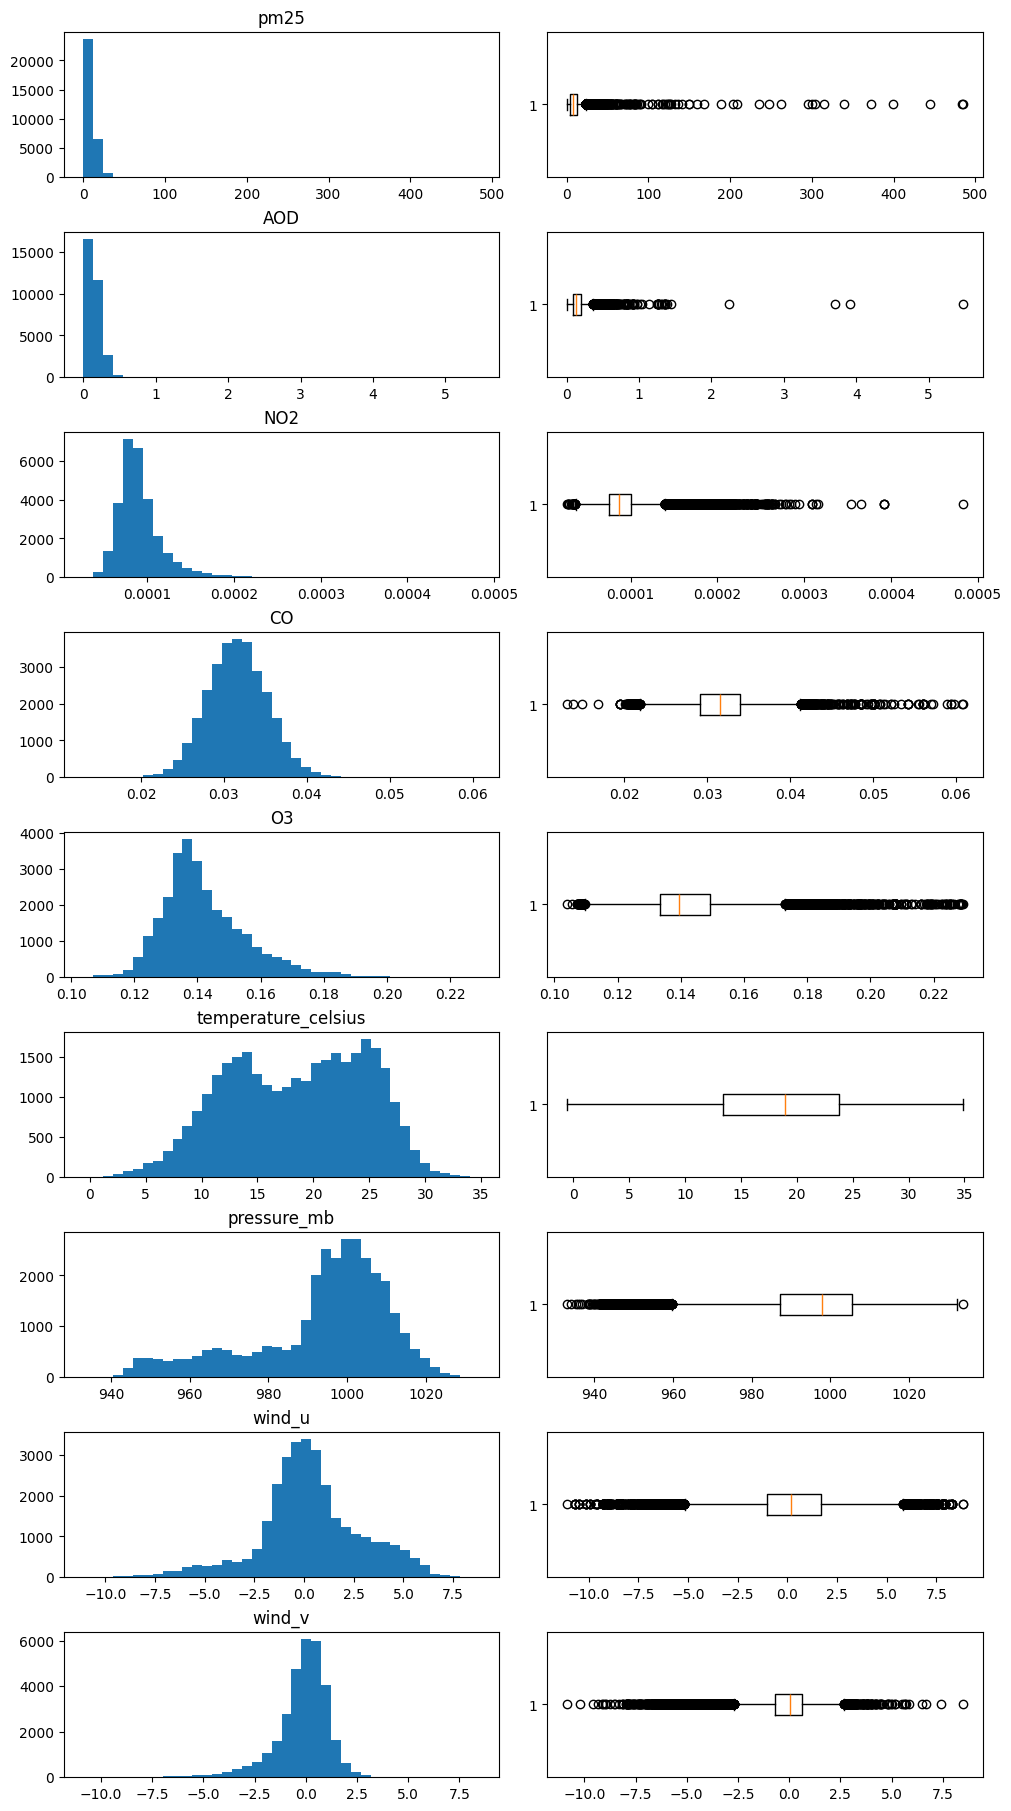

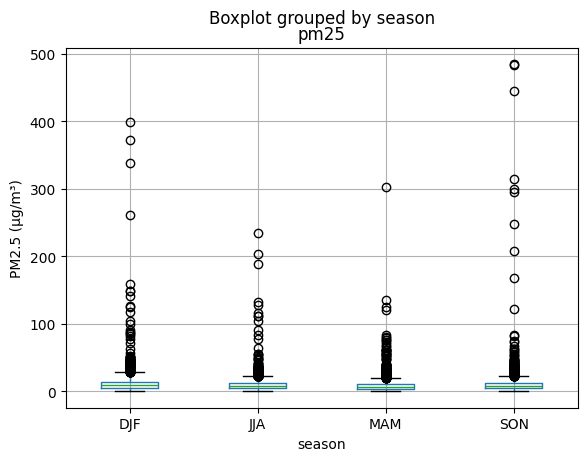

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct,skewness,kurtosis,iqr_flags
pm25,31286.0,9.317,10.344,0.007,4.542,7.733,12.000,484.982,0,0.000,19.113,666.646,1117
AOD,31286.0,0.152,0.106,0.000,0.083,0.131,0.197,5.475,0,0.000,8.649,306.555,834
NO2,28879.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2407,7.694,2.188,10.111,1563
CO,28879.0,0.032,0.004,0.013,0.029,0.032,0.034,0.061,2407,7.694,0.471,2.098,351
O3,28838.0,0.142,0.014,0.104,0.133,0.139,0.149,0.229,2448,7.825,1.252,3.047,1004
temperature_celsius,31286.0,18.485,6.194,-0.569,13.423,18.928,23.746,34.866,0,0.000,-0.170,-0.896,0
pressure_mb,31286.0,993.517,17.669,933.023,987.153,997.890,1005.462,1033.662,0,0.000,-1.019,0.428,2257
wind_u,31286.0,0.306,2.625,-11.099,-1.043,0.164,1.710,8.834,0,0.000,-0.219,0.902,1624
wind_v,31286.0,-0.172,1.361,-10.860,-0.695,0.049,0.651,8.486,0,0.000,-1.420,4.685,1775


In [ ]:
values = dev[variables]
summary = values.describe().T
summary['missing'] = values.isna().sum()
summary['missing_pct'] = values.isna().mean() * 100
summary['skewness'] = values.skew()
summary['kurtosis'] = values.kurt()
iqr = summary['75%'] - summary['25%']
summary['iqr_flags'] = (values.lt(summary['25%'] - 1.5*iqr) | values.gt(summary['75%'] + 1.5*iqr)).sum()
eda = [summary.rename_axis('variable').reset_index().assign(section='numeric_summary')]
counts = {name: int(mask.sum()) for name, mask in rules.items()}
counts.update(input_rows=len(data), clean_rows=len(clean), exact_duplicates_removed=exact_duplicates,
              audit_original_rows=41718, audit_removed_le_zero=727, audit_removed_ge_500=8)
eda.append(pd.Series(counts, name='value').rename_axis('variable').reset_index().assign(section='cleaning'))
eda.append(dev.groupby(['id','sensor_name']).size().rename('count').reset_index().assign(section='station_counts'))
for grouping in ['month', 'id']:
    missing = dev[gases].isna().groupby(dev[grouping])
    eda.append(missing.mean().mul(100).reset_index().assign(section=f'gas_missing_pct_by_{grouping}'))
    eda.append(missing.sum().reset_index().assign(section=f'gas_missing_count_by_{grouping}'))
for method in ['pearson', 'spearman']:
    matrix = values.corr(method=method)
    correlations = matrix.rename_axis(index='variable', columns='predictor').stack().rename('value').reset_index()
    correlations['high_predictor_correlation'] = (correlations.value.abs().gt(.9)
        & correlations.variable.ne(correlations.predictor)
        & correlations.variable.ne('pm25') & correlations.predictor.ne('pm25'))
    eda.append(correlations.assign(section=method))
    display(matrix.round(2))
for grouping in ['season', 'id']:
    eda.append(dev.groupby(grouping).apply(
        lambda g: g[predictors].corrwith(g.pm25, method='spearman')
    ).reset_index().assign(section=f'pm25_spearman_by_{grouping}'))
paired = dev[['pm25','AOD',*weather]].dropna()
design = np.column_stack([np.ones(len(paired)), paired[weather]])
observed = paired[['pm25','AOD']].to_numpy()
residuals = observed - design @ np.linalg.lstsq(design, observed, rcond=None)[0]
eda.append(pd.DataFrame({'section':['aod_weather_adjustment']*2,
                         'variable':['raw_pearson','weather_adjusted_pearson'],
                         'value':[paired.pm25.corr(paired.AOD),np.corrcoef(residuals.T)[0,1]]}))
fig, axes = plt.subplots(len(variables), 2, figsize=(10, 18), layout='constrained')
for name, (hist, box) in zip(variables, axes):
    hist.hist(dev[name].dropna(), bins=40)
    hist.set_title(name)
    box.boxplot(dev[name].dropna(), vert=False)
plt.show()
dev.boxplot(column='pm25', by='season')
plt.ylabel('PM2.5 (µg/m³)')
plt.show()
display(summary.round(3))

/tmp/ipykernel_540/1087625204.py:122: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "id": station, "metric": "ADF_p", "value": adfuller(longest)[1],
/tmp/ipykernel_540/1087625204.py:122: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "id": station, "metric": "ADF_p", "value": adfuller(longest)[1],
/tmp/ipykernel_540/1087625204.py:122: FutureWarning: adfuller currently retu

31,286 observations analysées dans 74 stations.


,id,first_day,last_day,observed_days,missing_days,one_day_intervals,multi_day_intervals,longest_run
0,0,2016-12-07,2022-03-12,727,1195,499,227,19
1,1,2016-11-25,2024-07-02,398,2379,272,125,16
2,2,2024-01-28,2024-12-31,236,103,174,61,22
3,5,2016-12-02,2022-02-27,726,1188,481,244,20
4,6,2016-12-02,2022-03-09,717,1207,484,232,20
5,7,2016-12-02,2024-12-30,319,2632,223,95,30
6,8,2018-05-29,2023-05-29,706,1121,443,262,20
7,9,2024-06-06,2024-09-30,89,28,75,13,29
8,10,2018-01-17,2024-09-09,310,2118,189,120,11
9,11,2016-12-02,2022-11-12,797,1375,509,287,18


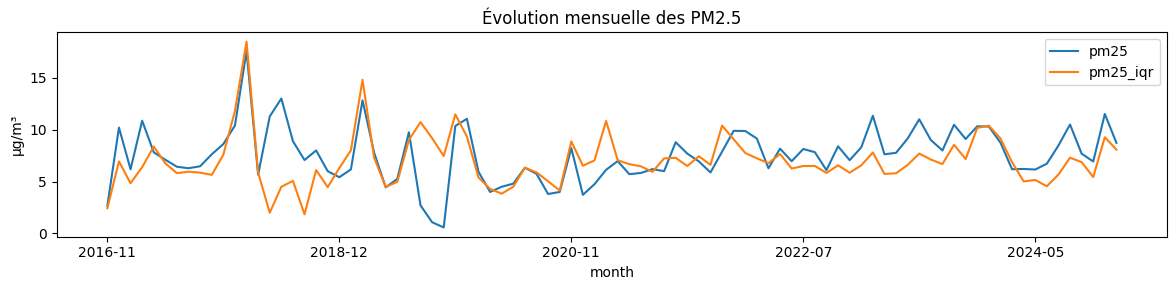

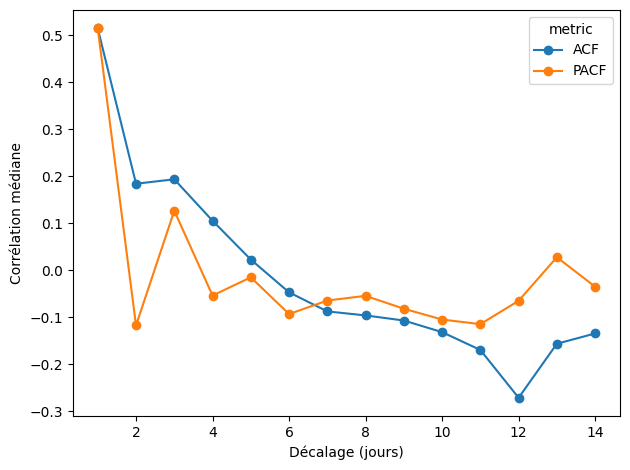

PM2.5 au-dessus de 25 µg/m³ : 2.70 %
PM2.5 au-dessus de 50 µg/m³ : 0.29 %
Fichier créé : Exploratory_temporal.csv


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import solve_toeplitz
from scipy.stats import chi2
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
try:
    from statsmodels.tsa.stattools import adfuller
except ImportError:
    adfuller = None

# 1. Charger les données si la cellule précédente n'a pas créé dev.
if "dev" not in globals():
    source = Path("/content/pm25_cleaned.csv")
    if not source.exists():
        from google.colab import files

        uploaded = files.upload()
        if source.name not in uploaded:
            raise ValueError("Sélectionne le fichier pm25_cleaned.csv.")
        source.write_bytes(uploaded[source.name])

    dev = pd.read_csv(source)

gases = ["NO2", "CO", "O3"]
variables = [
    "pm25", "AOD", *gases,
    "temperature_celsius", "pressure_mb", "wind_u", "wind_v",
]

dev = dev.copy()
dev[variables] = dev[variables].apply(pd.to_numeric, errors="coerce")
dev["date"] = pd.to_datetime(
    dev["date"], errors="coerce", utc=True
).dt.tz_convert(None).dt.normalize()

checks = {
    "invalid_dates": int(dev["date"].isna().sum()),
    "missing_station_ids": int(dev["id"].isna().sum()),
}

dev = dev.loc[
    dev["date"].lt("2025-01-01")
    & dev["id"].notna()
    & dev["pm25"].between(0, 500, inclusive="neither")
].copy()
dev = dev.drop_duplicates(subset=["id", "date", *variables])

if dev.empty:
    raise ValueError("Aucune observation valide avant 2025.")

checks["duplicate_station_days"] = int(dev.duplicated(["id", "date"]).sum())
if checks["duplicate_station_days"]:
    raise ValueError("Certaines stations ont plusieurs mesures différentes le même jour.")

dev["month"] = dev["date"].dt.to_period("M").astype(str)
dev["year"] = dev["date"].dt.year
dev["month_number"] = dev["date"].dt.month
dev["season"] = dev["month_number"].map(
    lambda month: ["DJF", "MAM", "JJA", "SON"][(month % 12) // 3]
)

temporal = [
    pd.Series(checks, name="value")
    .rename_axis("metric")
    .reset_index()
    .assign(section="metadata")
]

# 2. Compter les jours manquants et analyser les périodes sans interruption.
station_rows, diagnostics, timelines = [], [], []

for station, group in dev.groupby("id"):
    observed = group.set_index("date")[variables].sort_index()
    daily = observed.asfreq("D")
    timelines.append(daily.assign(id=station))

    intervals = observed.index.to_series().diff().dt.days
    segment_ids = intervals.ne(1).cumsum()
    segments = observed["pm25"].groupby(segment_ids)
    longest = max((segment for _, segment in segments), key=len)

    station_rows.append({
        "id": station,
        "first_day": daily.index.min(),
        "last_day": daily.index.max(),
        "observed_days": len(observed),
        "missing_days": len(daily) - len(observed),
        "one_day_intervals": int(intervals.eq(1).sum()),
        "multi_day_intervals": int(intervals.gt(1).sum()),
        "longest_run": len(longest),
    })

    if len(longest) < 30 or longest.nunique() < 2:
        continue

    centered = longest.to_numpy() - longest.mean()
    n_obs = len(centered)
    acf = np.correlate(centered, centered, mode="full")[n_obs - 1:n_obs + 14]
    acf = acf / acf[0]

    pacf = [1.0] + [
        solve_toeplitz(acf[:lag], acf[1:lag + 1])[-1]
        for lag in range(1, 15)
    ]

    lags = np.arange(1, 8)
    lb_stat = n_obs * (n_obs + 2) * np.sum(acf[lags] ** 2 / (n_obs - lags))
    diagnostics.append({
        "id": station, "metric": "Ljung_Box_p_lag_7",
        "value": chi2.sf(lb_stat, df=7),
    })

    if adfuller is not None:
        diagnostics.append({
            "id": station, "metric": "ADF_p", "value": adfuller(longest)[1],
        })

    for metric, coefficients in [("ACF", acf), ("PACF", pacf)]:
        for lag, value in enumerate(coefficients[1:], start=1):
            diagnostics.append({
                "id": station, "metric": metric, "lag": lag, "value": value,
            })

if adfuller is None:
    print("Test ADF ignoré car statsmodels n'est pas installé.")

coverage = pd.DataFrame(station_rows)
serial = pd.DataFrame(diagnostics, columns=["id", "metric", "lag", "value"])
temporal.extend([
    coverage.assign(section="station_coverage"),
    serial.assign(section="serial_diagnostics"),
])

# 3. Comparer les PM2.5 aux mesures météo et atmosphériques à différents décalages.
daily_panel = pd.concat(timelines).reset_index()
daily_panel["wind_speed"] = np.hypot(daily_panel["wind_u"], daily_panel["wind_v"])
lag_variables = ["AOD", *gases, "wind_speed", "temperature_celsius"]
pairs = []

for offset in range(-7, 8):
    shifted = daily_panel.groupby("id")[lag_variables].shift(offset)

    for name in lag_variables:
        pair = pd.concat([daily_panel["pm25"], shifted[name]], axis=1).dropna()
        correlation = np.nan
        if len(pair) >= 2 and pair.nunique().gt(1).all():
            correlation = pair["pm25"].corr(pair[name])

        pairs.append({
            "variable": name,
            "lag": offset,
            "value": correlation,
            "n_pairs": len(pair),
        })

temporal.append(pd.DataFrame(pairs).assign(section="lead_lag_pearson"))

# 4. Résumer les concentrations par mois, année et saison.
period_summaries = {}

for grouping in ["month", "year", "month_number", "season"]:
    grouped = dev.groupby(grouping, sort=True)
    drift = grouped[variables].median()
    drift["pm25_iqr"] = grouped["pm25"].quantile(0.75) - grouped["pm25"].quantile(0.25)
    drift["pct_above_25"] = grouped["pm25"].apply(lambda x: 100 * x.gt(25).mean())
    drift["pct_above_50"] = grouped["pm25"].apply(lambda x: 100 * x.gt(50).mean())
    drift["n"] = grouped.size()

    period_summaries[grouping] = drift
    temporal.append(drift.reset_index().assign(section=f"drift_by_{grouping}"))

# 5. Afficher et exporter les résultats.
print(f"{len(dev):,} observations analysées dans {len(coverage)} stations.")
display(coverage.head(10))

period_summaries["month"][["pm25", "pm25_iqr"]].plot(
    figsize=(12, 3), ylabel="µg/m³", title="Évolution mensuelle des PM2.5"
)
plt.tight_layout()
plt.show()

acf_pacf = serial.loc[serial["metric"].isin(["ACF", "PACF"])]
if not acf_pacf.empty:
    acf_pacf.groupby(["lag", "metric"])["value"].median().unstack().plot(
        marker="o", xlabel="Décalage (jours)", ylabel="Corrélation médiane"
    )
    plt.tight_layout()
    plt.show()

for threshold in [25, 50]:
    percentage = 100 * dev["pm25"].gt(threshold).mean()
    print(f"PM2.5 au-dessus de {threshold} µg/m³ : {percentage:.2f} %")

pd.concat(temporal, ignore_index=True, sort=False).to_csv(
    "Exploratory_temporal.csv", index=False
)
print("Fichier créé : Exploratory_temporal.csv")

In [ ]:
# 1. Associer chaque jour aux mesures de la veille pour la même station.
key = ["id", "date"]
observed = clean.sort_values(key).copy()

previous = observed[[*key, *predictors]].copy()
previous["date"] = previous["date"] + pd.Timedelta(days=1)
previous = previous.rename(columns={
    name: f"{name}_lag1" for name in predictors
})

model_data = observed[[*key, "pm25"]].merge(
    previous,
    on=key,
    how="left",
    validate="one_to_one",
    indicator=True,
)
model_data["previous_day_match"] = model_data.pop("_merge").eq("both")

# 2. Ajouter la position du jour dans l'année.
day_of_year = model_data["date"].dt.dayofyear
angle = 2 * np.pi * (day_of_year - 1) / 365.25
model_data["doy_sin"] = np.sin(angle)
model_data["doy_cos"] = np.cos(angle)

feature_names = [
    *(f"{name}_lag1" for name in predictors),
    "doy_sin",
    "doy_cos",
]
gas_lags = [f"{name}_lag1" for name in gases]

# 3. Créer un prétraitement réutilisable pour la partie 3.
def make_preprocessor(scale=True):
    numeric_steps = [
        ("median", SimpleImputer(strategy="median", keep_empty_features=True)),
    ]

    if scale:
        numeric_steps.append(("scale", StandardScaler()))

    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), feature_names),
        ("missing_gases", MissingIndicator(features="all"), gas_lags),
    ])

# 4. Vérifier le prétraitement sur deux périodes de développement.
# Entraînement jusqu'à fin 2023, puis validation à partir du 2 janvier 2024.
development = model_data.loc[model_data["date"].lt("2025-01-01")].copy()

train_demo = development.loc[
    development["date"].lt("2024-01-01"), feature_names
]
validation_demo = development.loc[
    development["date"].ge("2024-01-02"), feature_names
]

processor = make_preprocessor()
train_array = processor.fit_transform(train_demo)
validation_array = processor.transform(validation_demo)

assert np.isfinite(train_array).all(), "Valeurs non finies dans l'entraînement."
assert np.isfinite(validation_array).all(), "Valeurs non finies dans la validation."

print("Dimensions après prétraitement")
print("Entraînement :", train_array.shape)
print("Validation   :", validation_array.shape)
print(
    "Lignes de développement avec une observation la veille :",
    int(development["previous_day_match"].sum()),
)

# 5. Enregistrer les résultats de l'exploration.
pd.concat(eda, ignore_index=True, sort=False).to_csv(
    "Exploratory_Data.csv", index=False
)
pd.concat(temporal, ignore_index=True, sort=False).to_csv(
    "Exploratory_temporal.csv", index=False
)

print("Fichiers créés : Exploratory_Data.csv et Exploratory_temporal.csv")

Dimensions après prétraitement
Entraînement : (22598, 13)
Validation   : (8662, 13)
Lignes de développement avec une observation la veille : 20498
Fichier créé : Exploratory_temporal.csv


### 3RD **FEATURE CORRELATION ANALYSIS**

In [ ]:
# ============================================================
# PART 3 – FEATURE CORRELATION ANALYSIS
# STEP 1 – LOAD AND VALIDATE DEVELOPMENT DATA
# ============================================================

from pathlib import Path
from itertools import product
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. LOAD THE CLEANED CSV
path = Path("/content/pm25_cleaned.csv")

if path.exists():
    data = pd.read_csv(path)
else:
    uploaded = files.upload()
    if path.name not in uploaded:
        raise ValueError("Sélectionne le fichier pm25_cleaned.csv.")
    data = pd.read_csv(BytesIO(uploaded[path.name]))

predictors = [
    "AOD", "NO2", "CO", "O3",
    "temperature_celsius", "pressure_mb", "wind_u", "wind_v",
]
# 2. DEFINE THE STATION-DATE KEY
keys = ["id", "date"]

required = {*keys, "pm25", *predictors}
missing_columns = required.difference(data.columns)
if missing_columns:
    raise ValueError(f"Colonnes manquantes dans le CSV : {sorted(missing_columns)}")

data["date"] = pd.to_datetime(
    data["date"], errors="coerce", utc=True
).dt.tz_convert(None).dt.normalize()

numeric_columns = ["pm25", *predictors]
data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors="coerce")
data[numeric_columns] = data[numeric_columns].replace([np.inf, -np.inf], np.nan)

# Utiliser les observations jusqu'à fin 2024.
# 3. KEEP VALID OBSERVATIONS THROUGH 2024
data = data.loc[
    data["date"].lt("2025-01-01")
    & data["id"].notna()
    & data["pm25"].between(0, 500, inclusive="neither")
].sort_values(keys).copy()

if data.empty:
    raise ValueError("Aucune observation valide avant 2025.")
if data.duplicated(keys).any():
    raise ValueError("Le CSV contient plusieurs lignes pour une même station et date.")

print(f"{len(data):,} observations chargées dans {data['id'].nunique()} stations.")

31,286 observations chargées dans 74 stations.


In [ ]:
# ============================================================
# PART 3 – FEATURE CORRELATION ANALYSIS
# STEP 2 – COMPUTE AND EXPORT CORRELATIONS
# ============================================================

# Associer les mesures de la veille aux PM2.5 du jour, par station.
# 1. ALIGN PREVIOUS-DAY MEASUREMENTS BY STATION
previous = data[[*keys, *predictors]].copy()
previous["date"] += pd.Timedelta(days=1)
previous = previous.rename(columns={name: f"{name}_lag1" for name in predictors})

aligned = data[[*keys, "pm25"]].merge(
    previous, on=keys, how="left", validate="one_to_one"
)

# 2. CREATE CYCLICAL CALENDAR FEATURES
angle = 2 * np.pi * (aligned["date"].dt.dayofyear - 1) / 365.25
aligned["doy_sin"] = np.sin(angle)
aligned["doy_cos"] = np.cos(angle)
features = [f"{name}_lag1" for name in predictors] + ["doy_sin", "doy_cos"]

# 3. FLAG MISSING GAS MEASUREMENTS
for gas in ["NO2", "CO", "O3"]:
    name = f"{gas}_lag1_missing"
    aligned[name] = aligned[f"{gas}_lag1"].isna().astype(int)
    features.append(name)

# Calculer les corrélations avant imputation.
# 4. CALCULATE PEARSON AND SPEARMAN ON AVAILABLE PAIRS
rows = []

for feature in features:
    pairs = aligned[[feature, "pm25"]].dropna()
    pearson = np.nan
    spearman = np.nan

    if len(pairs) >= 2 and pairs.nunique().gt(1).all():
        pearson = pairs[feature].corr(pairs["pm25"], method="pearson")
        spearman = pairs[feature].corr(pairs["pm25"], method="spearman")

    rows.append({
        "Feature": feature,
        "Pearson": pearson,
        "Spearman": spearman,
        "Available pairs": len(pairs),
        "Missing (%)": 100 * aligned[feature].isna().mean(),
    })

# 5. RANK AND EXPORT FEATURE-TARGET CORRELATIONS
table_3 = pd.DataFrame(rows).sort_values(
    "Spearman", key=lambda scores: scores.abs(), ascending=False
).reset_index(drop=True)

print("Table 3 — Feature Correlation Analysis")
display(table_3.round(3))
table_3.to_csv("Table_3_Feature_Correlation_Analysis.csv", index=False)

# Repérer les variables d'entrée fortement corrélées entre elles.
# 6. IDENTIFY STRONGLY CORRELATED PREDICTOR PAIRS
matrix = aligned[features].corr(method="pearson")
upper = np.triu(np.ones(matrix.shape, dtype=bool), k=1)
strong_pairs = (
    matrix.where(upper & matrix.abs().gt(0.90))
    .rename_axis(index="Feature 1", columns="Feature 2")
    .stack()
    .rename("Pearson")
    .reset_index()
)

print("Paires de variables avec |Pearson| > 0.90")
display(strong_pairs.round(3))

Table 3 — Feature Correlation Analysis


,Feature,Pearson,Spearman,Available pairs,Missing (%)
0,NO2_lag1,0.153,0.219,18841,39.778
1,pressure_mb_lag1,0.114,0.174,20498,34.482
2,O3_lag1,-0.096,-0.140,18831,39.810
3,wind_u_lag1,-0.058,-0.115,20498,34.482
4,doy_cos,0.088,0.077,31286,0.000
5,AOD_lag1,0.032,0.072,20498,34.482
6,wind_v_lag1,0.038,0.055,20498,34.482
7,CO_lag1_missing,-0.020,-0.052,31286,0.000
8,NO2_lag1_missing,-0.020,-0.052,31286,0.000
9,O3_lag1_missing,-0.019,-0.052,31286,0.000


Paires de variables avec |Pearson| > 0.90


,Feature 1,Feature 2,Pearson
0,NO2_lag1_missing,CO_lag1_missing,1.000
1,NO2_lag1_missing,O3_lag1_missing,0.999
2,CO_lag1_missing,O3_lag1_missing,0.999


4TH **TEMPORAL ANALYSIS (ARMA/ARIMA)**

Station 81 — 760 mesures d'entraînement
Validation en 2024 — 20 mesures observées
ADF sur 21 jours consécutifs — p = 0.7702


/tmp/ipykernel_540/521293752.py:33: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f"ADF sur {len(continuous)} jours consécutifs — p = {adfuller(continuous)[1]:.4f}")


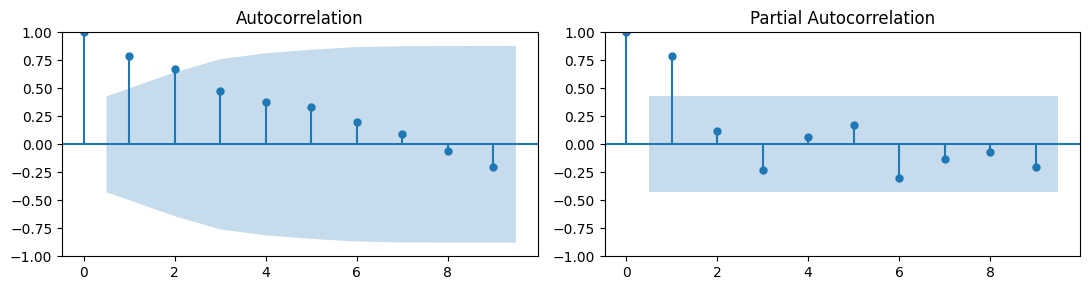

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Table 4 — ARMA and ARIMA Validation


,"Order (p, d, q)",Training AIC,Validation observations,MAE,RMSE
Model,,,,,
ARMA,"(2, 0, 2)",4211.196,20,4.814,6.228
ARIMA,"(1, 1, 2)",4205.427,20,5.038,6.347
Persistence,,NaN,20,6.135,8.187


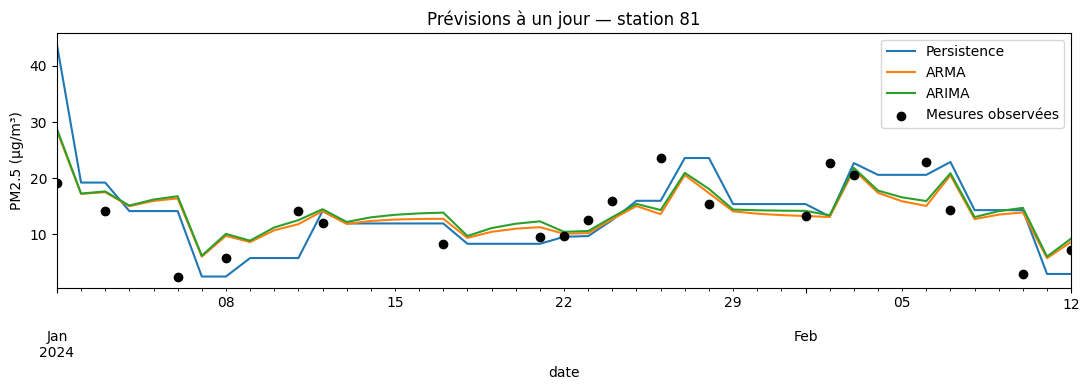

In [ ]:
# ============================================================
# PART 4 – TEMPORAL ANALYSIS (ARMA/ARIMA)
# STEP 1 – SELECT A STATION AND EXAMINE THE TRAINING SERIES
# ============================================================

# Choisir automatiquement une station avec des mesures dans les deux périodes.
# 1. SET THE CHRONOLOGICAL SPLIT
cutoff = pd.Timestamp("2024-01-01")
train_counts = data.loc[data["date"].lt(cutoff)].groupby("id").size()
valid_counts = data.loc[data["date"].ge(cutoff)].groupby("id").size()

eligible = train_counts[
    train_counts.ge(30) & train_counts.index.isin(valid_counts[valid_counts.ge(5)].index)
]

if eligible.empty:
    raise ValueError("Aucune station n'a assez de mesures pour la comparaison.")

# 2. SELECT A STATION WITH OBSERVATIONS IN BOTH PERIODS
station = eligible.idxmax()

# Garder une ligne par jour. Les jours sans observation restent à NaN.
series = (
    data.loc[data["id"].eq(station)]
    .set_index("date")["pm25"]
    .asfreq("D")
)
train = series.loc[series.index < cutoff]
validation = series.loc[series.index >= cutoff]

print(f"Station {station} — {train.count()} mesures d'entraînement")
print(f"Validation en 2024 — {validation.count()} mesures observées")

# Diagnostics sur le plus long bloc d'entraînement sans jour manquant.
# 3. FIND THE LONGEST CONTINUOUS TRAINING BLOCK
observed_train = train.dropna()
blocks = observed_train.index.to_series().diff().dt.days.ne(1).cumsum()
continuous = max((part for _, part in observed_train.groupby(blocks)), key=len)

if len(continuous) >= 20 and continuous.nunique() > 2:
    print(f"ADF sur {len(continuous)} jours consécutifs — p = {adfuller(continuous)[1]:.4f}")
    lags = min(14, len(continuous) // 2 - 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    plot_acf(continuous, lags=lags, ax=axes[0])
    plot_pacf(continuous, lags=lags, method="ywm", ax=axes[1])
    plt.tight_layout()
    plt.show()
else:
    print("Bloc continu trop court ou trop peu variable pour les diagnostics.")

# La référence reprend la dernière mesure connue avant le jour prédit.
# 4. BUILD THE PERSISTENCE BASELINE
predictions = pd.DataFrame({
    "Observed": validation,
    "Persistence": series.ffill().shift(1).reindex(validation.index),
})
results = [{"Model": "Persistence", "Order (p, d, q)": "", "Training AIC": np.nan}]

# ARMA correspond à d=0. La comparaison ARIMA utilise d=1.
# 5. SELECT ARMA AND ARIMA ORDERS USING TRAINING AIC
for name, d in [("ARMA", 0), ("ARIMA", 1)]:
    candidates = []

    for p, q in product(range(3), repeat=2):
        order = (p, d, q)
        if order == (0, 0, 0):
            continue

        try:
            fitted = ARIMA(train, order=order).fit()
        except (ValueError, np.linalg.LinAlgError):
            continue

        if fitted.mle_retvals.get("converged", False) and np.isfinite(fitted.aic):
            candidates.append((fitted.aic, order, fitted))

    if not candidates:
        raise RuntimeError(f"Aucun modèle {name} n'a convergé.")

    aic, order, state = min(candidates, key=lambda candidate: candidate[0])

    # Prévoir le jour J avant d'intégrer sa mesure pour le jour suivant.
    forecasts = []
    for date in validation.index:
        forecasts.append(float(state.forecast(steps=1).iloc[0]))
        state = state.extend(validation.loc[[date]])

    predictions[name] = forecasts
    results.append({"Model": name, "Order (p, d, q)": str(order), "Training AIC": aic})

# Calculer les erreurs sur les mêmes jours observés pour les trois méthodes.

# ============================================================
# PART 5 – MODEL EVALUATION
# STEP 1 – COMPARE VALIDATION ERRORS AND PLOT FORECASTS
# ============================================================

# 1. COMPARE ERRORS ON THE SAME OBSERVED DATES
scored = predictions.replace([np.inf, -np.inf], np.nan).dropna()
if scored.empty:
    raise ValueError("Aucune date commune pour calculer les erreurs.")

errors = scored.drop(columns="Observed").sub(scored["Observed"], axis=0)
table_4 = pd.DataFrame(results).set_index("Model")
table_4["Validation observations"] = len(scored)
table_4["MAE"] = errors.abs().mean()
table_4["RMSE"] = errors.pow(2).mean().pow(0.5)
table_4 = table_4.sort_values("RMSE")

print("Table 4 — ARMA and ARIMA Validation")
display(table_4.round(3))
# 2. EXPORT THE VALIDATION TABLE
table_4.to_csv("Table_4_ARMA_ARIMA_Validation.csv")

# 3. PLOT FORECASTS AND OBSERVED MEASUREMENTS
ax = predictions.drop(columns="Observed").plot(
    figsize=(11, 4),
    ylabel="PM2.5 (µg/m³)",
    title=f"Prévisions à un jour — station {station}",
)
actual = validation.dropna()
ax.scatter(actual.index, actual, color="black", label="Mesures observées", zorder=3)
ax.legend()
plt.tight_layout()
plt.show()